<a href="https://colab.research.google.com/github/Abidau/PCVK_Ganjil_26-27/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Naufal Abid Aurizky'
NIM  = '244107020212'

N = int(NIM[-3:])
PARAM = {
    'b'    : (N % 61) + 20,
    'a'    : round(1.0 + (N % 9) / 10, 1),
    'c'    : (N % 20) + 30,
    'gamma': round(0.4 + (N % 6) * 0.25, 2),
    'bit'  : (N % 6) + 2,
}
waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA   :', NAMA)
print('NIM    :', NIM)
for k, v in PARAM.items():
    print('%-6s :' % k, v)
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA   : Naufal Abid Aurizky
NIM    : 244107020212
b      : 49
a      : 1.5
c      : 42
gamma  : 0.9
bit    : 4
WAKTU  : 2026-11-08 18:05:00 WIB
SISTEM : 3.13.18 Linux-6.6.159+-x86_64-with-glibc2.39
TOKEN  : 56e331a356473acf


# D1. Praktikum Deteksi Obyek Dasar

In [32]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

NIM  = globals().get('NIM', '244107020212')
BASE = '/content/drive/MyDrive/PCVK/Images/' + NIM

# ===== Fungsi bantu: mencari file di Google Drive & menampilkan gambar =====
import os, difflib, tempfile, urllib.request

ROOT_PCVK = os.path.dirname(os.path.dirname(BASE))        # .../MyDrive/PCVK
EKSTENSI  = ('.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff')
_indeks   = {}

def segarkan_indeks():
    """Petakan nama file/folder -> path lengkap. Folder NIM (BASE) diprioritaskan, lalu seluruh folder PCVK."""
    berkas, folder = {}, {}
    for akar in (BASE, ROOT_PCVK):
        for dp, dn, fn in os.walk(akar):
            for d in dn: folder.setdefault(d.lower(), os.path.join(dp, d))
            for f in fn: berkas.setdefault(f.lower(), os.path.join(dp, f))
    _indeks['berkas'], _indeks['folder'] = berkas, folder

def cari_file(nama, persis=False):
    if not _indeks: segarkan_indeks()
    kunci = os.path.basename(nama).lower()
    if kunci in _indeks['berkas']:
        return _indeks['berkas'][kunci]
    if not persis:                                          # toleran terhadap salah ketik nama file
        mirip = difflib.get_close_matches(kunci, list(_indeks['berkas']), n=1, cutoff=0.8)
        if mirip:
            return _indeks['berkas'][mirip[0]]
    raise FileNotFoundError(f"File '{nama}' tidak ditemukan di {BASE} maupun {ROOT_PCVK}. "
                            "Pastikan Drive sudah di-mount dan file sudah ada di folder tersebut.")

def cari_folder(nama):
    if not _indeks: segarkan_indeks()
    if nama.lower() in _indeks['folder']:
        return _indeks['folder'][nama.lower()]
    raise FileNotFoundError(f"Folder '{nama}' tidak ditemukan di {BASE} maupun {ROOT_PCVK}.")

def gambar_di(folder, rekursif=False):
    """Daftar path gambar di sebuah folder (terurut)."""
    hasil = []
    if rekursif:
        for dp, _, fn in os.walk(folder):
            hasil += [os.path.join(dp, f) for f in fn if f.lower().endswith(EKSTENSI)]
    else:
        hasil = [os.path.join(folder, f) for f in os.listdir(folder) if f.lower().endswith(EKSTENSI)]
    return sorted(hasil)

def baca_path(path, mode=cv.IMREAD_COLOR):
    img = cv.imread(path, mode)
    if img is None:
        raise IOError(f'Gagal membaca gambar: {path}')
    return img

def baca_bgr(nama):  return baca_path(cari_file(nama), cv.IMREAD_COLOR)
def baca_gray(nama): return baca_path(cari_file(nama), cv.IMREAD_GRAYSCALE)
def rgb(img):        return cv.cvtColor(img, cv.COLOR_BGR2RGB)

def tampil(img, judul='', ukuran=(8, 8)):
    plt.figure(figsize=ukuran)
    plt.imshow(img, cmap='gray' if img.ndim == 2 else None)
    plt.title(judul)
    plt.show()

print('BASE      :', BASE, '| ada:', os.path.isdir(BASE))
print('ROOT PCVK :', ROOT_PCVK, '| ada:', os.path.isdir(ROOT_PCVK))

BASE      : /content/drive/MyDrive/PCVK/Images/244107020212 | ada: True
ROOT PCVK : /content/drive/MyDrive/PCVK | ada: True


In [33]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Template Matching (6 metode OpenCV)

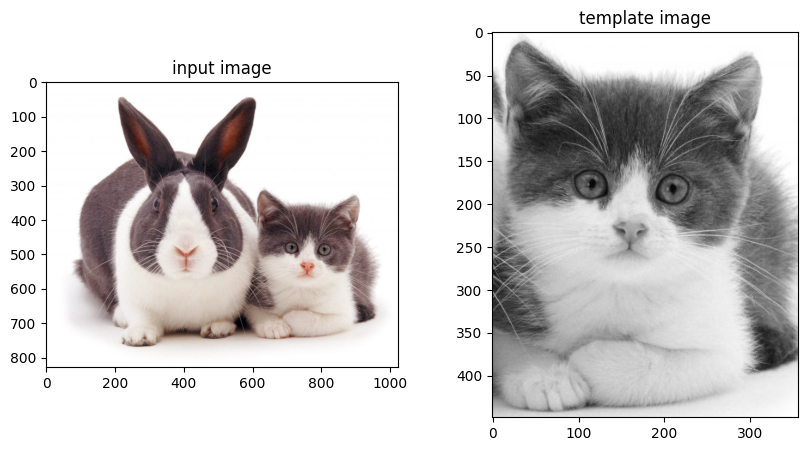

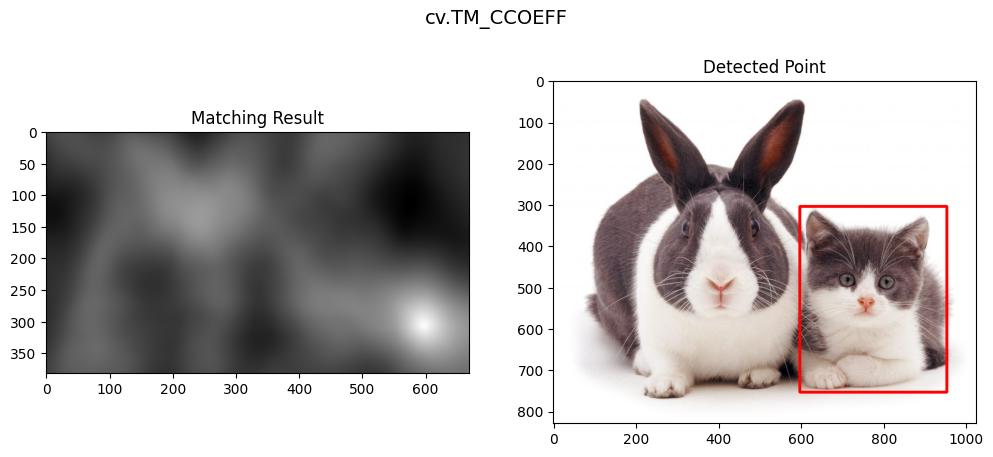

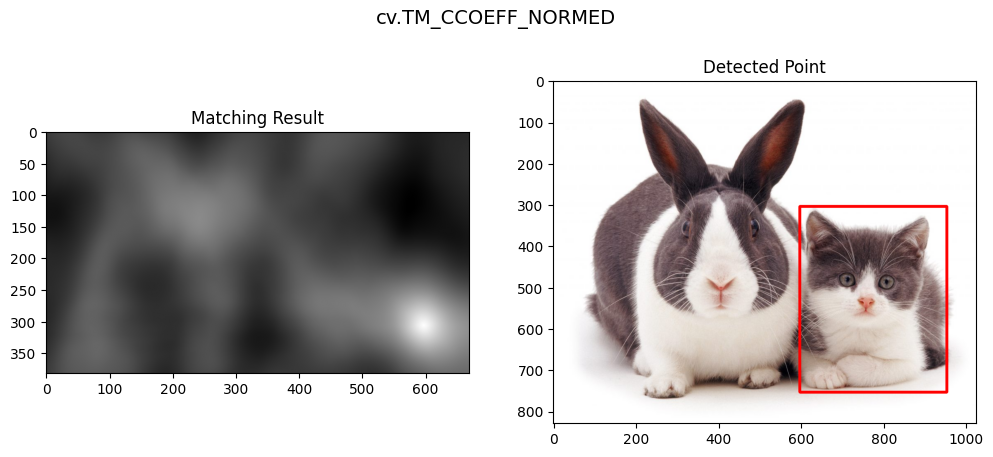

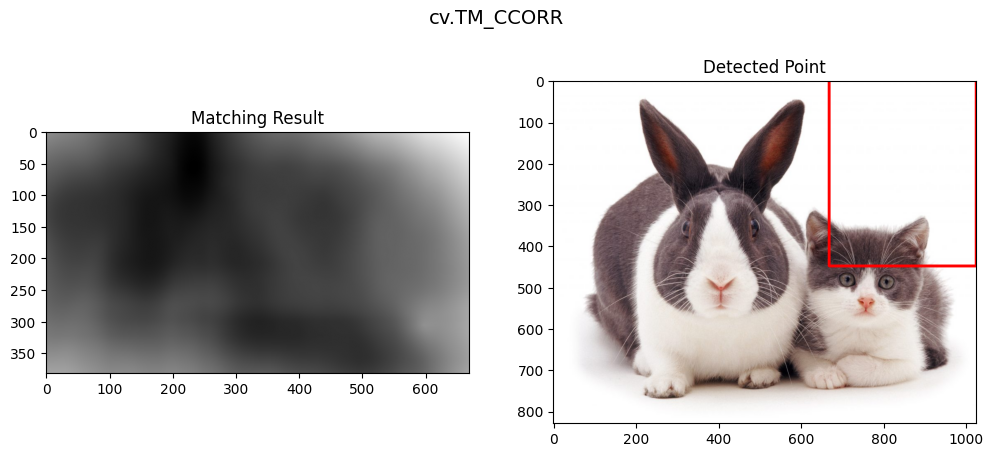

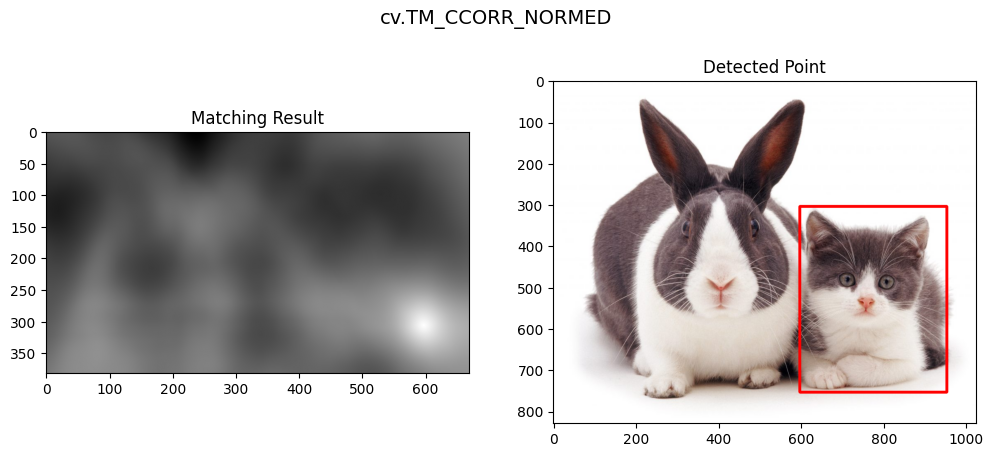

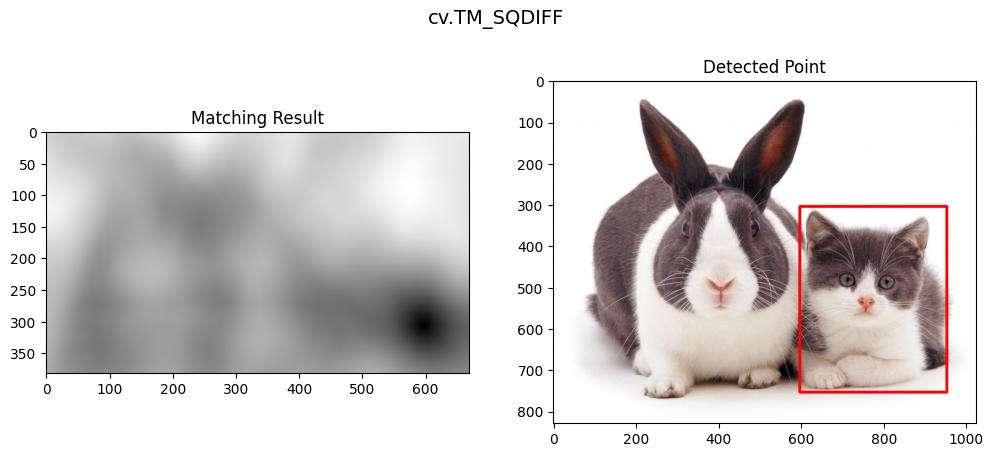

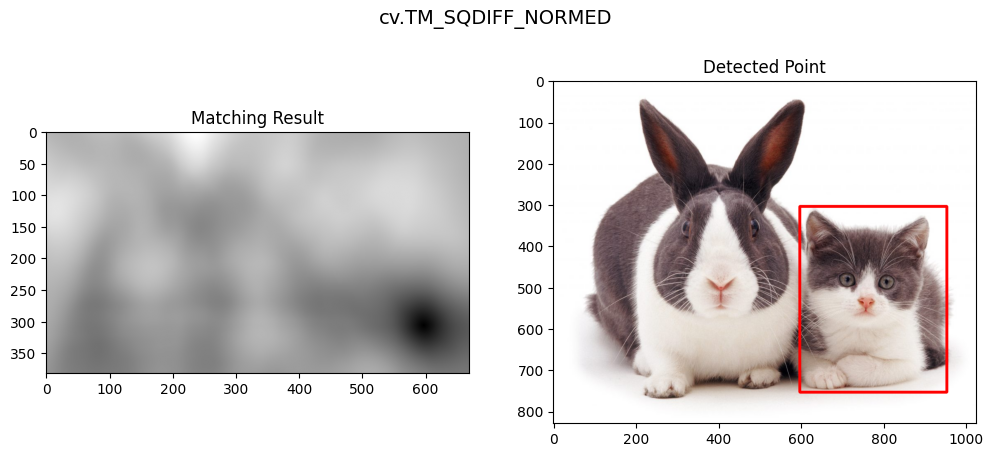

In [34]:
img_bgr  = baca_bgr('cats_and_bunnies.jpg')
img_rgb  = rgb(img_bgr)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
templ    = baca_gray('cat2_templatejpg.jpg')

if templ.shape[0] > img_gray.shape[0] or templ.shape[1] > img_gray.shape[1]:
    f = min(img_gray.shape[0] / templ.shape[0], img_gray.shape[1] / templ.shape[1]) * 0.9
    templ = cv.resize(templ, None, fx=f, fy=f)
h, w = templ.shape

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img_rgb);               ax[0].set_title('input image')
ax[1].imshow(templ, cmap='gray');    ax[1].set_title('template image')
plt.show()

daftar_metode = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
                 'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

for nama_metode in daftar_metode:
    method = getattr(cv, nama_metode.split('.')[1])
    res = cv.matchTemplate(img_gray, templ, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    if method in (cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED):
        top_left = min_loc
    else:
        top_left = max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)

    hasil = img_rgb.copy()
    cv.rectangle(hasil, top_left, bottom_right, (255, 0, 0), max(2, img_rgb.shape[1] // 200))

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(nama_metode, fontsize=14)
    ax[0].imshow(res, cmap='gray');  ax[0].set_title('Matching Result')
    ax[1].imshow(hasil);             ax[1].set_title('Detected Point')
    plt.show()

## 3. template Matching multi-objek tanpa 'cv.matchTemplate'

In [35]:
from numpy.lib.stride_tricks import sliding_window_view
from scipy.ndimage import gaussian_filter, label

def buat_mask(templ, ambang=2, min_piksel=30):
    gelap = templ <= ambang
    lab, n = label(gelap)
    mask = np.ones(templ.shape, np.float32)
    for i in range(1, n + 1):
        komp = lab == i
        menyentuh_tepi = komp[0].any() or komp[-1].any() or komp[:, 0].any() or komp[:, -1].any()
        if komp.sum() >= min_piksel and menyentuh_tepi:
            mask[komp] = 0
    return mask

def gradien(img, sigma=1.0):
    gy, gx = np.gradient(gaussian_filter(img.astype(np.float32), sigma))
    return np.hypot(gx, gy)

def ncc_mask(citra, templ, mask):
    citra = citra.astype(np.float32); templ = templ.astype(np.float32)
    th, tw = templ.shape
    n = mask.sum()
    t0 = (templ - (templ * mask).sum() / n) * mask
    t_norm = np.sqrt((t0 ** 2).sum()) + 1e-8
    H, W = citra.shape
    R = np.zeros((H - th + 1, W - tw + 1), np.float32)
    for y in range(R.shape[0]):
        win = sliding_window_view(citra[y:y + th], (th, tw))[0]
        mu = (win * mask).sum(axis=(1, 2), keepdims=True) / n
        w0 = (win - mu) * mask
        num = (w0 * t0).sum(axis=(1, 2))
        den = np.sqrt((w0 ** 2).sum(axis=(1, 2))) * t_norm
        R[y] = num / (den + 1e-8)
    return R

def peta_skor(citra, templ):
    mask = buat_mask(templ)
    R_int  = ncc_mask(citra, templ, mask)
    R_grad = ncc_mask(gradien(citra), gradien(templ), mask)
    return np.sqrt(np.clip(R_int, 0, None) * np.clip(R_grad, 0, None)), mask

def ambil_kandidat(R, th, tw, min_skor=0.05, maks=20):
    R = R.copy(); hasil = []
    while len(hasil) < maks:
        v = R.max()
        if v < min_skor:
            break
        y, x = np.unravel_index(R.argmax(), R.shape)
        hasil.append((int(x), int(y), float(v)))
        R[max(0, y - th // 2):y + th // 2 + 1, max(0, x - tw // 2):x + tw // 2 + 1] = -1
    return hasil

def batas_otsu(skor):
    s = np.sort(np.array(skor))
    terbaik, batas = -1, s.min()
    for k in range(1, len(s)):
        a, b = s[:k], s[k:]
        var = len(a) * len(b) * (a.mean() - b.mean()) ** 2
        if var > terbaik:
            terbaik, batas = var, (s[k - 1] + s[k]) / 2
    return batas

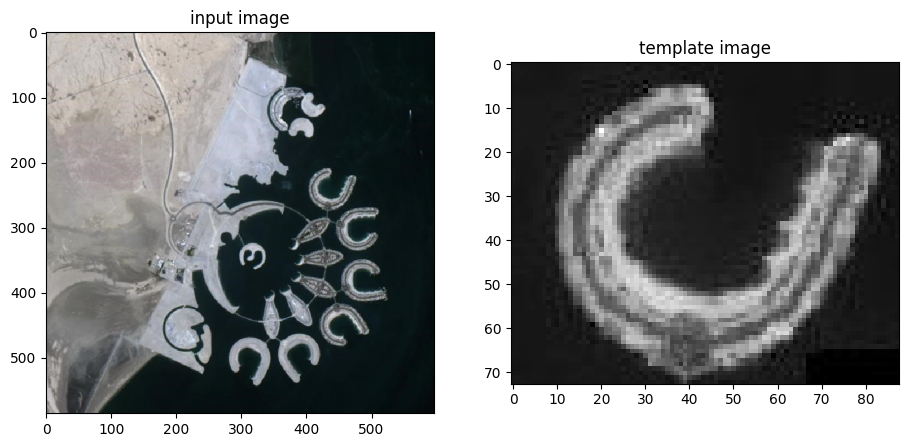

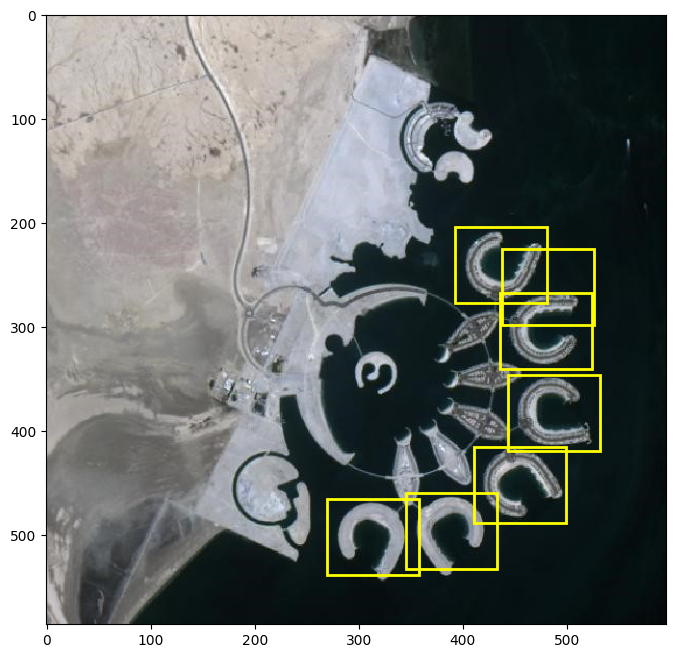

In [36]:
import matplotlib.patches as patches

bahrain_bgr  = baca_bgr('bahrain.jpg')
bahrain_gray = cv.cvtColor(bahrain_bgr, cv.COLOR_BGR2GRAY)
bahrain_tmpl = baca_gray('bahrain-template.jpg')
th, tw = bahrain_tmpl.shape

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(rgb(bahrain_bgr));            ax[0].set_title('input image')
ax[1].imshow(bahrain_tmpl, cmap='gray');   ax[1].set_title('template image')
plt.show()

R, mask = peta_skor(bahrain_gray, bahrain_tmpl)
kandidat = ambil_kandidat(R, th, tw)

sisa = kandidat[1:15]
BATAS_OTOMATIS = batas_otsu([v for _, _, v in sisa])

BATAS_MANUAL = None
BATAS = BATAS_MANUAL if BATAS_MANUAL is not None else BATAS_OTOMATIS

objek = [kandidat[0]] + [o for o in sisa if o[2] >= BATAS]

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(rgb(bahrain_bgr))
for x, y, v in objek:
    ax.add_patch(patches.Rectangle((x, y), tw, th, edgecolor='yellow', fill=False, linewidth=2))
plt.show()

## 4. Edge Detection (Sobel, Canny, Laplacian)

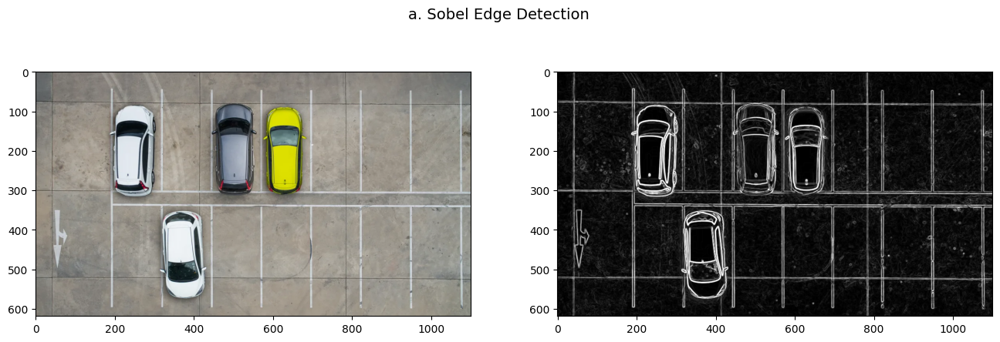

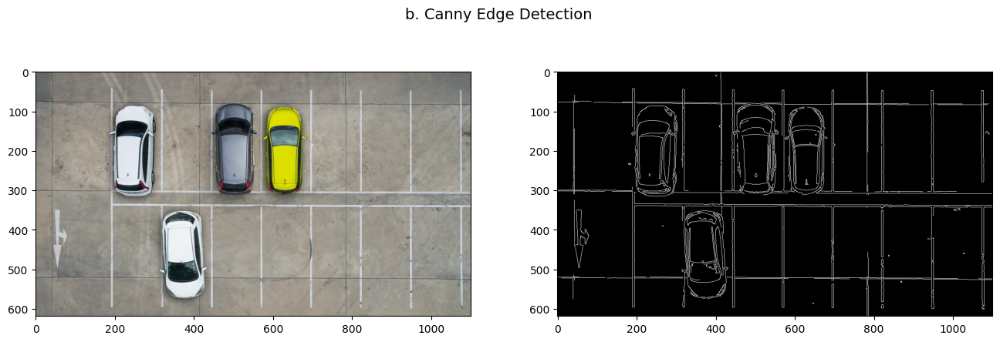

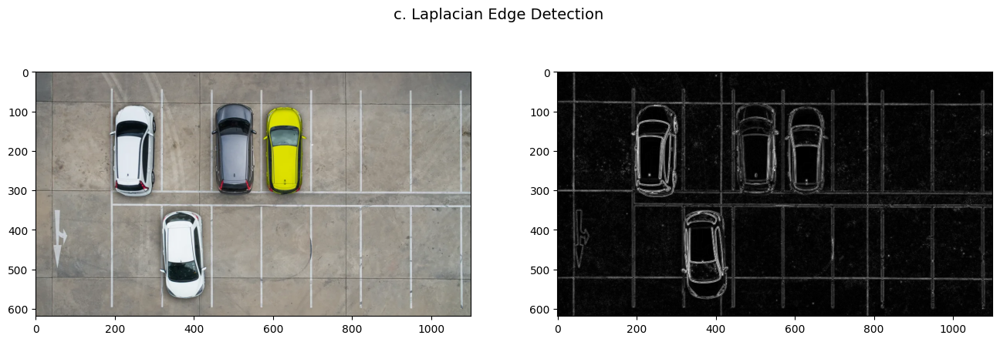

In [37]:
car_bgr  = baca_bgr('car-park.jpg')
car_rgb  = rgb(car_bgr)
car_gray = cv.cvtColor(car_bgr, cv.COLOR_BGR2GRAY)
car_blur = cv.GaussianBlur(car_gray, (3, 3), 0)

def dua_kolom(hasil, judul):
    fig, ax = plt.subplots(1, 2, figsize=(16, 5))
    ax[0].imshow(car_rgb)
    ax[1].imshow(hasil, cmap='gray')
    fig.suptitle(judul, fontsize=14)
    plt.show()

# a. Sobel
sobelx = cv.Sobel(car_blur, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(car_blur, cv.CV_64F, 0, 1, ksize=3)
sobel  = cv.convertScaleAbs(cv.magnitude(sobelx, sobely))
dua_kolom(sobel, 'a. Sobel Edge Detection')

# b. Canny
canny = cv.Canny(car_blur, 100, 200)
dua_kolom(canny, 'b. Canny Edge Detection')

# c. Laplacian
lap = cv.convertScaleAbs(cv.Laplacian(car_blur, cv.CV_64F, ksize=3))
dua_kolom(lap, 'c. Laplacian Edge Detection')

## 5. Corner Detection (Harris & Shi-Tomasi)

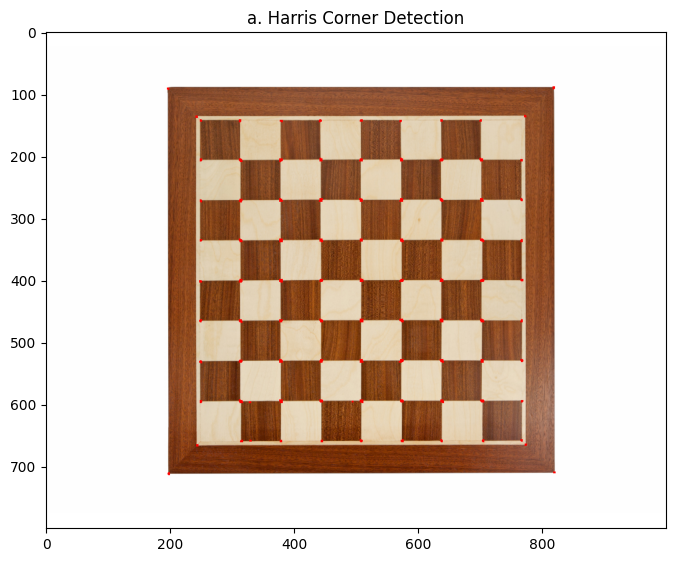

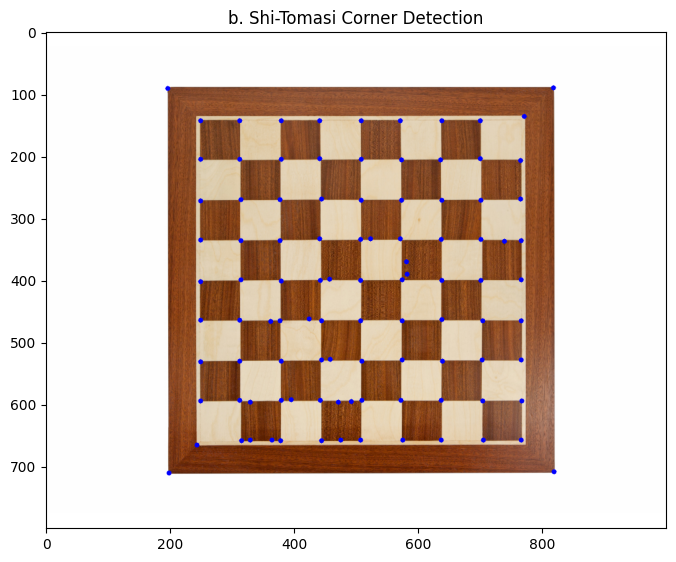

In [38]:
chess_bgr  = baca_bgr('chess-board.jpg')
chess_rgb  = rgb(chess_bgr)
chess_gray = cv.cvtColor(chess_bgr, cv.COLOR_BGR2GRAY)

# a. Harris Corner Detection
gray32 = np.float32(chess_gray)
dst = cv.cornerHarris(gray32, blockSize=2, ksize=3, k=0.04)
dst = cv.dilate(dst, None)
harris = chess_rgb.copy()
harris[dst > 0.01 * dst.max()] = [255, 0, 0]          # sudut ditandai merah
tampil(harris, 'a. Harris Corner Detection', ukuran=(8, 8))

# b. Shi-Tomasi (goodFeaturesToTrack)
corners = cv.goodFeaturesToTrack(chess_gray, maxCorners=100, qualityLevel=0.01, minDistance=10)
corners = np.int32(corners)
shi = chess_rgb.copy()
for c in corners:
    x, y = c.ravel()
    cv.circle(shi, (int(x), int(y)), 4, (0, 0, 255), -1)   # titik biru (gambar sudah RGB)
tampil(shi, 'b. Shi-Tomasi Corner Detection', ukuran=(8, 8))

## 6. Grid Detection dengan Hough Transform

Orientasi grid (derajat): [159.5  72.5]
Threshold Hough: 157 | jumlah garis akhir: 20


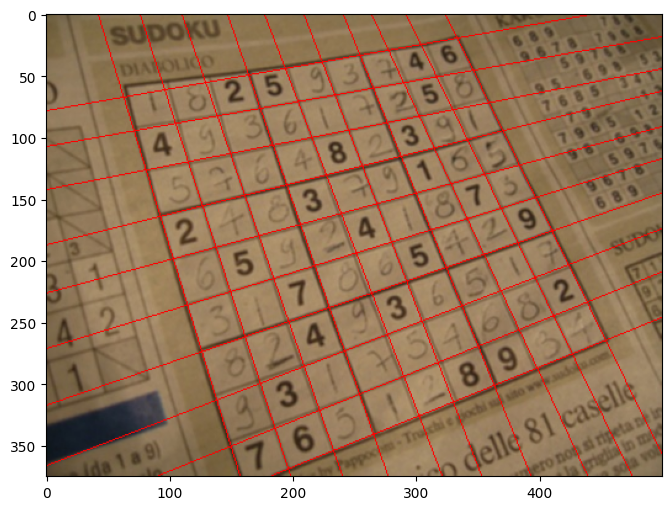

In [39]:
sudoku_bgr  = baca_bgr('sudoku.jpg')
sudoku_rgb  = rgb(sudoku_bgr)
sudoku_gray = cv.cvtColor(sudoku_bgr, cv.COLOR_BGR2GRAY)

H, W = sudoku_gray.shape
ukuran = min(H, W)

# 1. Canny (diblur dulu agar tekstur kertas/noise tidak ikut jadi tepi)
blur  = cv.GaussianBlur(sudoku_gray, (5, 5), 0)
edges = cv.Canny(blur, 50, 150, apertureSize=3)
# 2. Dilasi (gabungkan tepi ganda pada garis grid)
kernel = np.ones((3, 3), np.uint8)
dilasi = cv.dilate(edges, kernel, iterations=1)
# 3. Erosi (tipiskan kembali agar Hough tidak mendeteksi terlalu banyak garis)
erosi = cv.erode(dilasi, kernel, iterations=1)

def orientasi_dominan():
    gx = cv.Sobel(blur, cv.CV_32F, 1, 0)
    gy = cv.Sobel(blur, cv.CV_32F, 0, 1)
    m  = erosi > 0
    sudut = np.arctan2(gy, gx)[m] % np.pi
    bobot = np.hypot(gx, gy)[m]
    hist, _ = np.histogram(sudut, bins=180, range=(0, np.pi), weights=bobot)
    hist = np.convolve(np.r_[hist[-3:], hist, hist[:3]], np.ones(5) / 5, mode='same')[3:-3]
    p1 = int(hist.argmax())
    idx = [(p1 + 90 + k) % 180 for k in range(-30, 31)]
    p2 = idx[int(np.argmax(hist[idx]))]
    return np.deg2rad(np.array([p1, p2], dtype=float) + 0.5)

def pilih_dan_gabung(lines, phi, per_arah=10, tol_sudut=np.deg2rad(8), d_pos=15, d_theta=np.deg2rad(8)):
    c = np.array([W / 2, H / 2])
    jumlah = [0, 0]
    diterima = []
    for r, t in lines:
        sel = np.abs((t - phi + np.pi / 2) % np.pi - np.pi / 2)
        arah = int(sel.argmin())
        if sel[arah] > tol_sudut or jumlah[arah] >= per_arah:
            continue
        jarak = r - c @ np.array([np.cos(t), np.sin(t)])
        mirip = False
        for r2, t2, j2 in diterima:
            if abs((t - t2 + np.pi / 2) % np.pi - np.pi / 2) < d_theta:
                j_cmp = jarak if abs(t - t2) < np.pi / 2 else -jarak
                if abs(j_cmp - j2) < d_pos:
                    mirip = True
                    break
        if not mirip:
            diterima.append((float(r), float(t), float(jarak)))
            jumlah[arah] += 1
    return [(r, t) for r, t, _ in diterima]

phi = orientasi_dominan()
print('Orientasi grid (derajat):', np.rad2deg(phi).round(1))

JUMLAH_TARGET = 20
garis, THRESH = [], None
for thr in range(int(0.9 * ukuran), 40, -5):
    lines = cv.HoughLines(erosi, 1, np.pi / 180, thr)
    if lines is None:
        continue
    kandidat = pilih_dan_gabung(lines[:, 0, :], phi)
    if kandidat:
        garis, THRESH = kandidat, thr
    if len(kandidat) >= JUMLAH_TARGET:
        break
print('Threshold Hough:', THRESH, '| jumlah garis akhir:', len(garis))

hasil = sudoku_rgb.copy()
L = int(np.hypot(H, W))
for rho, theta in garis:
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    p1 = (int(x0 - L * b), int(y0 + L * a))
    p2 = (int(x0 + L * b), int(y0 - L * a))
    cv.line(hasil, p1, p2, (255, 0, 0), 1)

plt.figure(figsize=(8, 6))
plt.imshow(hasil)
plt.show()

## 7. Counter Detection

Jumlah kontur: 31


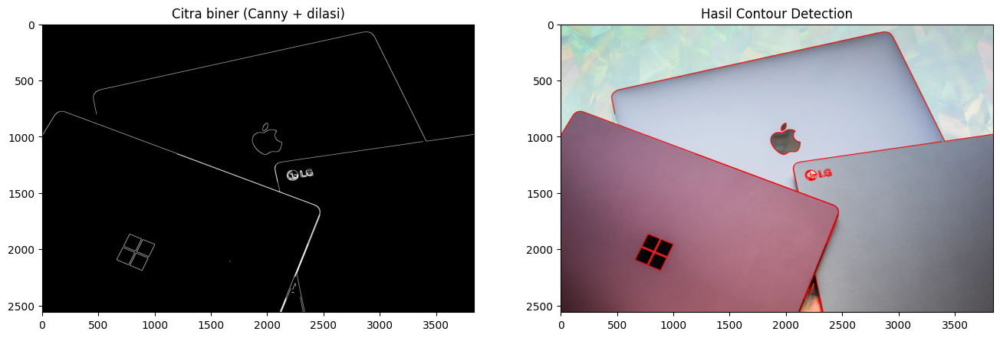

In [40]:
laptop_bgr  = baca_bgr('laptop.jpg')
laptop_rgb  = rgb(laptop_bgr)
laptop_gray = cv.cvtColor(laptop_bgr, cv.COLOR_BGR2GRAY)

# 1. Ubah ke citra biner (tepi Canny), lalu dilasi agar tepi tersambung
blur  = cv.GaussianBlur(laptop_gray, (5, 5), 0)
biner = cv.Canny(blur, 50, 150)
biner = cv.dilate(biner, np.ones((3, 3), np.uint8), iterations=1)

# 2. Cari kontur
contours, hierarchy = cv.findContours(biner, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)
MIN_PANJANG = 50
contours = [c for c in contours if cv.arcLength(c, True) > MIN_PANJANG]
print('Jumlah kontur:', len(contours))

# 3. Gambar kontur
hasil = laptop_rgb.copy()
cv.drawContours(hasil, contours, -1, (255, 0, 0), max(2, hasil.shape[1] // 800))

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
ax[0].imshow(biner, cmap='gray');  ax[0].set_title('Citra biner (Canny + dilasi)')
ax[1].imshow(hasil);               ax[1].set_title('Hasil Contour Detection')
plt.show()

# D2. Praktikum Feature Matching dan Face Detection

## 8. Face Detection

In [42]:
import sys, subprocess

subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '--upgrade', '--no-deps',
                       '--target', '/content/cv4_lib', 'opencv-python-headless==4.11.0.86'])

# muat ulang cv2 dari folder tersebut
for k in [m for m in sys.modules if m == 'cv2' or m.startswith('cv2.')]:
    del sys.modules[k]
sys.path.insert(0, '/content/cv4_lib')

import cv2 as cv
print('OpenCV aktif :', cv.__version__)
print('CascadeClassifier:', hasattr(cv, 'CascadeClassifier'), '| SIFT:', hasattr(cv, 'SIFT_create'))

OpenCV aktif : 4.11.0
CascadeClassifier: True | SIFT: True


Folder facedet : /content/drive/MyDrive/PCVK/Images/244107020212/facedet
Gambar diproses: ['jokowi.jpg', 'kartini.jpg', 'kucing.jpg', 'mask.png', 'mjordan.jpg', 'solvayconf.jpg']


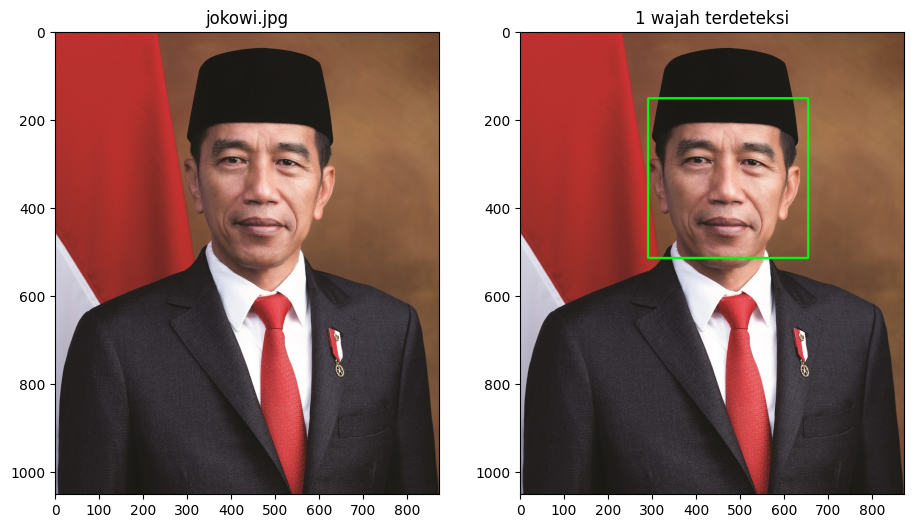

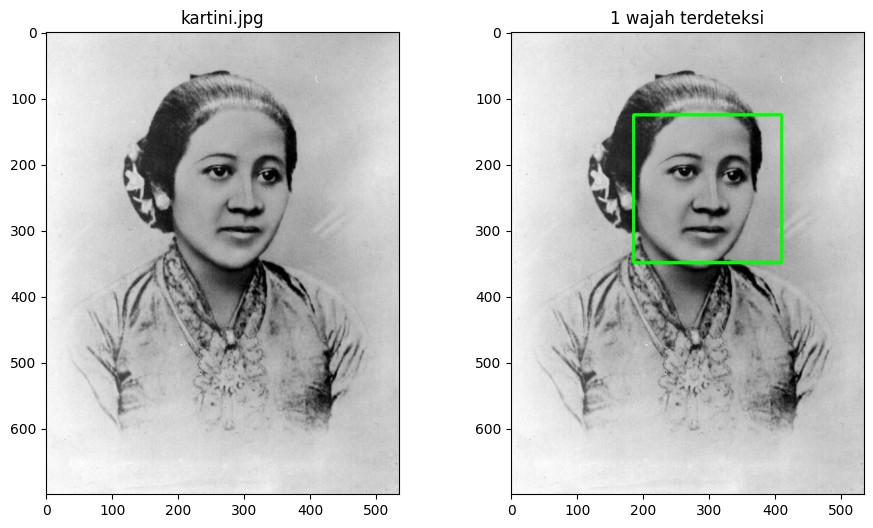

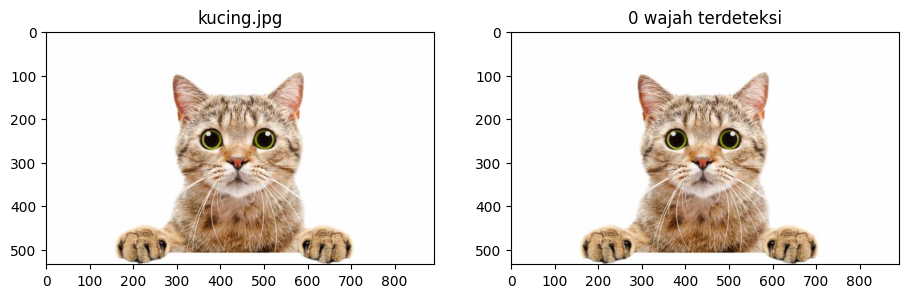

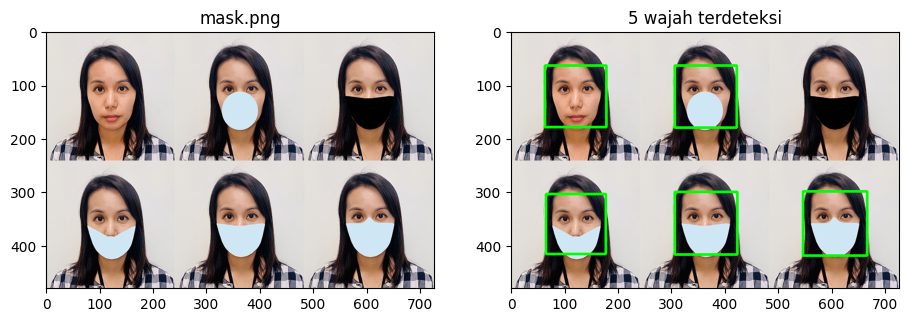

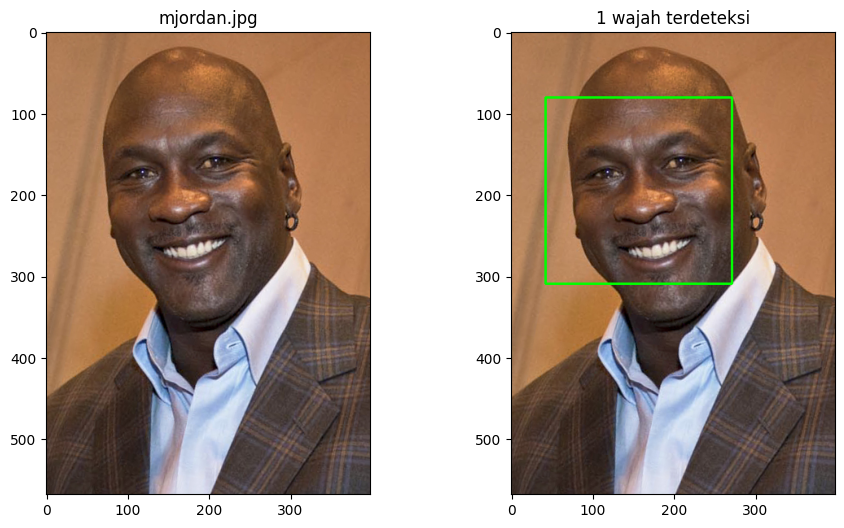

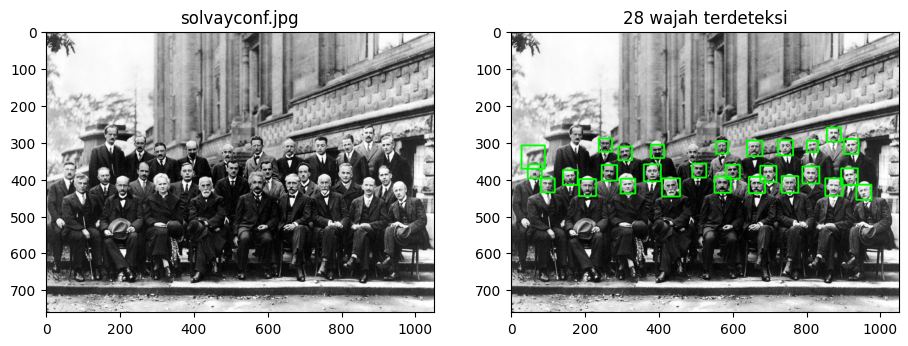

In [43]:
URL_CASCADE = 'https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/'

def muat_cascade(nama_xml):
    """Urutan pencarian: folder haarcascades di Drive -> bawaan OpenCV -> unduh dari GitHub OpenCV."""
    if not hasattr(cv, 'CascadeClassifier'):
        raise RuntimeError(f'OpenCV {cv.__version__} tidak memiliki CascadeClassifier (OpenCV 5). '
                           'Jalankan sel "Pastikan OpenCV 4.x" di bagian atas notebook, lalu Run all dari atas.')
    kandidat = []
    try:
        kandidat.append(cari_file(nama_xml, persis=True))
    except FileNotFoundError:
        pass
    kandidat.append(os.path.join(getattr(getattr(cv, 'data', None), 'haarcascades', ''), nama_xml))
    for p in kandidat:
        if os.path.isfile(p):
            c = cv.CascadeClassifier(p)
            if not c.empty():
                return c
    tujuan = os.path.join(tempfile.gettempdir(), nama_xml)
    urllib.request.urlretrieve(URL_CASCADE + nama_xml, tujuan)
    c = cv.CascadeClassifier(tujuan)
    if c.empty():
        raise RuntimeError(f'Gagal memuat cascade {nama_xml}')
    return c

def tebal_garis(img):
    return max(2, int(round(max(img.shape[:2]) / 250)))

def pilih_gambar(kata_kunci, folder, kecuali=()):
    """Gambar di `folder` yang namanya memuat salah satu kata kunci (dan tidak memuat kata 'kecuali')."""
    hasil = []
    for p in gambar_di(folder):
        n = os.path.basename(p).lower()
        if any(k in n for k in kata_kunci) and not any(k in n for k in kecuali):
            hasil.append(p)
    return hasil

cascade_wajah = muat_cascade('haarcascade_frontalface_alt.xml')

FOLDER_FACEDET = cari_folder('facedet')
KECUALI = ('reeses', 'cereal', 'people', 'ktm')
berkas_wajah = [p for p in gambar_di(FOLDER_FACEDET)
                if not any(k in os.path.basename(p).lower() for k in KECUALI)]
print('Folder facedet :', FOLDER_FACEDET)
print('Gambar diproses:', [os.path.basename(p) for p in berkas_wajah])

for p in berkas_wajah:
    asli = baca_path(p)
    gray = cv.cvtColor(asli, cv.COLOR_BGR2GRAY)
    roi_wajah = cascade_wajah.detectMultiScale(gray)
    hasil = asli.copy()
    for (x, y, w, h) in roi_wajah:
        cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), tebal_garis(hasil))

    fig, ax = plt.subplots(1, 2, figsize=(11, 6))
    ax[0].imshow(rgb(asli));   ax[0].set_title(os.path.basename(p))
    ax[1].imshow(rgb(hasil));  ax[1].set_title(f'{len(roi_wajah)} wajah terdeteksi')
    plt.show()

## 9. Deteksi Wajah Kucing

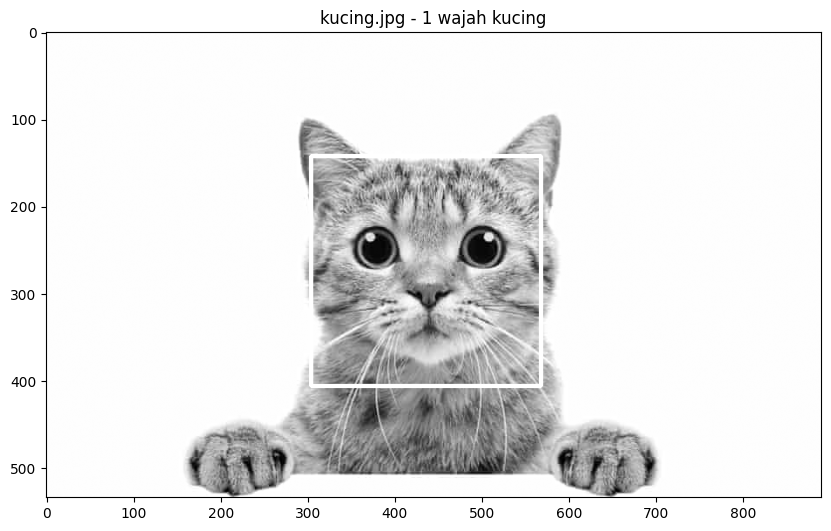

In [44]:
# 9. Deteksi wajah kucing (cascade khusus kucing bawaan OpenCV)
cascade_kucing_ext = muat_cascade('haarcascade_frontalcatface_extended.xml')
cascade_kucing     = muat_cascade('haarcascade_frontalcatface.xml')

def hapus_kotak_bersarang(kotak):
    """Buang kotak yang pusatnya berada di dalam kotak lain yang lebih besar
    (mis. kotak kecil di hidung yang berada di dalam kotak wajah)."""
    kotak = sorted([tuple(int(v) for v in k) for k in kotak], key=lambda k: k[2] * k[3], reverse=True)
    simpan = []
    for (x, y, w, h) in kotak:
        cx, cy = x + w / 2, y + h / 2
        if any(X <= cx <= X + W and Y <= cy <= Y + H for X, Y, W, H in simpan):
            continue
        simpan.append((x, y, w, h))
    return simpan

def deteksi_kucing(gray, maks=1):
    """Deteksi wajah kucing. minSize relatif terhadap gambar (mencegah kotak kecil di hidung/mata),
    minNeighbors tinggi (kurangi false positive), lalu hanya kotak terbesar yang dipertahankan."""
    ukuran = int(min(gray.shape[:2]) * 0.25)
    for casc in (cascade_kucing_ext, cascade_kucing):
        for mn in (6, 4, 3):
            r = casc.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=mn, minSize=(ukuran, ukuran))
            if len(r):
                return hapus_kotak_bersarang(r)[:maks]
    return []

FILE_KUCING = None
nama   = lambda p: os.path.basename(p).lower()
gambar = [p for p in gambar_di(FOLDER_FACEDET, rekursif=True) if not any(k in nama(p) for k in ('reeses', 'cereal', 'ktm', 'bunnies', 'template'))]
if FILE_KUCING:
    file_kucing = [cari_file(FILE_KUCING)]
else:
    file_kucing = [p for p in gambar if any(k in nama(p) for k in ('cat', 'kucing'))] or \
                  [p for p in gambar
                   if not len(cascade_wajah.detectMultiScale(baca_path(p, cv.IMREAD_GRAYSCALE)))
                   and len(deteksi_kucing(baca_path(p, cv.IMREAD_GRAYSCALE)))]
if not file_kucing:
    raise FileNotFoundError(f'Gambar kucing tidak ditemukan. Isi facedet: {[os.path.basename(p) for p in gambar]}')

for p in file_kucing:
    kucing = baca_path(p, cv.IMREAD_GRAYSCALE)
    roi_kucing = deteksi_kucing(kucing)
    hasil = kucing.copy()
    for (x, y, w, h) in roi_kucing:
        cv.rectangle(hasil, (x, y), (x + w, y + h), 255, tebal_garis(hasil))
    plt.figure(figsize=(10, 10))
    plt.imshow(hasil, cmap='gray')
    plt.title(f'{os.path.basename(p)} - {len(roi_kucing)} wajah kucing')
    plt.show()


## 10. Eye Detection pada wajah

Gambar: jokowi.jpg


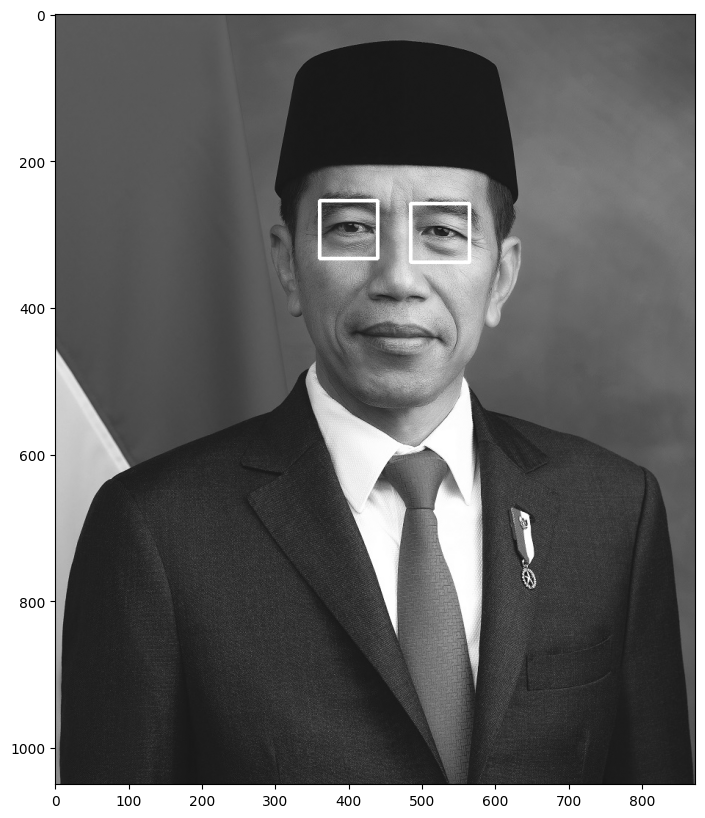

In [45]:
cascade_mata = muat_cascade('haarcascade_eye.xml')

def kewarnaan(p):
    """0 = abu-abu; makin besar makin berwarna."""
    b, g, r = [c.astype(np.float32) for c in cv.split(cv.imread(p))]
    return float(np.hypot(np.abs(r - g).std(), np.abs(0.5 * (r + g) - b).std()))

def jumlah_wajah(p):
    g = cv.imread(p, cv.IMREAD_GRAYSCALE)
    return len(cascade_wajah.detectMultiScale(g, 1.1, 4, minSize=(int(0.03 * g.shape[1]),) * 2))

FILE_PRABOWO = None
gambar = [p for p in gambar_di(FOLDER_FACEDET, rekursif=True) if not any(k in os.path.basename(p).lower() for k in ('reeses', 'cereal', 'ktm', 'people'))]
if FILE_PRABOWO:
    file_prabowo = cari_file(FILE_PRABOWO)
else:
    calon = [p for p in gambar if 'prabowo' in os.path.basename(p).lower()] or \
            [p for p in gambar if cv.imread(p).shape[0] > cv.imread(p).shape[1] and jumlah_wajah(p) == 1]
    if not calon:
        raise FileNotFoundError(f'Foto Pak Prabowo tidak ditemukan. Isi facedet: {[os.path.basename(p) for p in gambar]}')
    file_prabowo = max(calon, key=kewarnaan)
print('Gambar:', os.path.basename(file_prabowo))
prabowo = baca_path(file_prabowo, cv.IMREAD_GRAYSCALE)
hasil = prabowo.copy()

for (x, y, w, h) in cascade_wajah.detectMultiScale(prabowo):
    roi = prabowo[y:y + int(h * 0.65), x:x + w]
    for (ex, ey, ew, eh) in cascade_mata.detectMultiScale(roi, scaleFactor=1.1, minNeighbors=5):
        cv.rectangle(hasil, (x + ex, y + ey), (x + ex + ew, y + ey + eh), 255, tebal_garis(hasil) // 2 + 1)

plt.figure(figsize=(10, 10))
plt.imshow(hasil, cmap='gray')
plt.show()

## 11. Deteksi Senyuman pada Gambar People

Gambar: mask.png
Wajah ke- | skor senyum | status
    1     |     2.69     | SENYUM
    2     |     0.00     | -
    3     |     0.00     | -
    4     |     0.00     | -
    5     |     0.00     | -


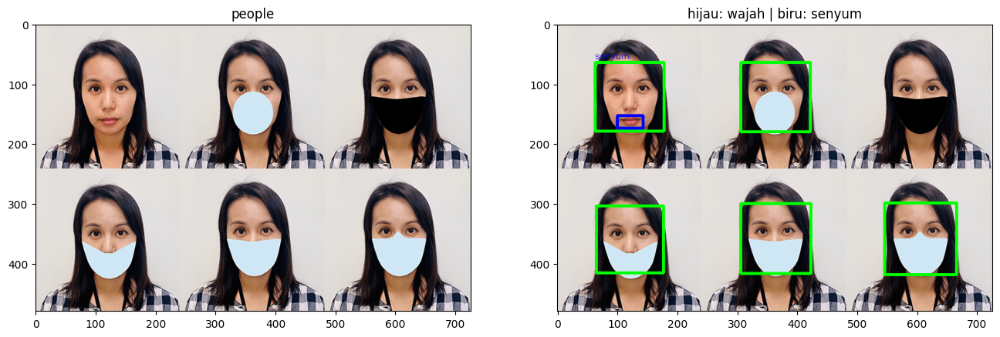

In [46]:
cascade_senyum = muat_cascade('haarcascade_smile.xml')
AMBANG_SENYUM = 2.0

def kewarnaan(p):
    """0 = abu-abu; makin besar makin berwarna."""
    b, g, r = [c.astype(np.float32) for c in cv.split(cv.imread(p))]
    return float(np.hypot(np.abs(r - g).std(), np.abs(0.5 * (r + g) - b).std()))

def jumlah_wajah(p):
    g = cv.imread(p, cv.IMREAD_GRAYSCALE)
    return len(cascade_wajah.detectMultiScale(g, 1.1, 4, minSize=(int(0.03 * g.shape[1]),) * 2))

FILE_PEOPLE = None
gambar = [p for p in gambar_di(FOLDER_FACEDET, rekursif=True) if not any(k in os.path.basename(p).lower() for k in ('reeses', 'cereal', 'ktm'))]
if FILE_PEOPLE:
    file_people = cari_file(FILE_PEOPLE)
else:
    calon = [p for p in gambar if 'people' in os.path.basename(p).lower()] or \
            [p for p in gambar if cv.imread(p).shape[1] > 1.3 * cv.imread(p).shape[0] and jumlah_wajah(p) >= 5]
    if not calon:
        raise FileNotFoundError(f'Gambar people tidak ditemukan. Isi facedet: {[os.path.basename(p) for p in gambar]}')
    file_people = max(calon, key=kewarnaan)
print('Gambar:', os.path.basename(file_people))
people = baca_path(file_people)
gray = cv.cvtColor(people, cv.COLOR_BGR2GRAY)
H, W = gray.shape

wajah = cascade_wajah.detectMultiScale(gray, 1.1, 4, minSize=(int(0.04 * W), int(0.04 * W)))
wajah = sorted(wajah.tolist(), key=lambda f: (int(f[1] / (H / 2)), f[0]))
hasil = people.copy()
t = tebal_garis(hasil)
print('Wajah ke- | skor senyum | status')
for i, (x, y, w, h) in enumerate(wajah, 1):
    cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), t)
    oy = y + int(h * 0.5)
    roi = gray[oy:y + h, x:x + w]
    skala = max(1.0, 200.0 / w)
    roi = cv.equalizeHist(cv.resize(roi, None, fx=skala, fy=skala, interpolation=cv.INTER_CUBIC))
    kotak, _, bobot = cascade_senyum.detectMultiScale3(
        roi, scaleFactor=1.3, minNeighbors=4,
        minSize=(int(roi.shape[1] * 0.3), int(roi.shape[0] * 0.15)), outputRejectLevels=True)
    skor = float(np.max(bobot)) if len(bobot) else 0.0
    senyum = skor >= AMBANG_SENYUM
    if senyum:
        sx, sy, sw, sh = kotak[int(np.argmax(np.ravel(bobot)))]
        sx, sy, sw, sh = [int(v / skala) for v in (sx, sy, sw, sh)]
        cv.rectangle(hasil, (x + sx, oy + sy), (x + sx + sw, oy + sy + sh), (255, 0, 0), t)
        cv.putText(hasil, 'senyum', (x, max(12, y - 6)), cv.FONT_HERSHEY_SIMPLEX, max(0.4, W / 1500), (255, 0, 0), max(1, t // 2))
    print(f'{i:^9} | {skor:^12.2f} | {"SENYUM" if senyum else "-"}')

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
ax[0].imshow(rgb(people));  ax[0].set_title('people')
ax[1].imshow(rgb(hasil));   ax[1].set_title('hijau: wajah | biru: senyum')
plt.show()

## 12. Face Trecking menggunakan Google Colab (kamera)

<IPython.core.display.Javascript object>

Foto disimpan: foto_face_tracking_1.jpg (1 wajah)
Face tracking selesai (38 frame diproses).


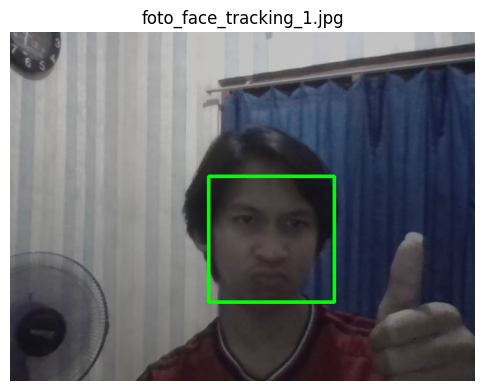

In [49]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode, b64encode

def video_stream():
    js = Javascript("""
    var video, div = null, stream, captureCanvas, imgElement, labelElement;
    var pendingResolve = null, shutdown = false, wantCapture = false;

    function removeDom() {
      stream.getVideoTracks()[0].stop();
      video.remove(); div.remove();
      video = null; div = null; stream = null; imgElement = null; captureCanvas = null; labelElement = null;
    }
    function onAnimationFrame() {
      if (!shutdown) { window.requestAnimationFrame(onAnimationFrame); }
      if (pendingResolve) {
        var result = "";
        if (!shutdown) {
          captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
          result = captureCanvas.toDataURL('image/jpeg', 0.8);
        }
        var lp = pendingResolve; pendingResolve = null; lp(result);
      }
    }
    async function createDom() {
      if (div !== null) { return stream; }
      div = document.createElement('div');
      div.style.border = '2px solid black'; div.style.padding = '3px';
      div.style.width = '100%'; div.style.maxWidth = '600px';
      document.body.appendChild(div);

      const modelOut = document.createElement('div');
      modelOut.innerHTML = "<span>Status: </span>";
      labelElement = document.createElement('span');
      labelElement.innerText = 'No data'; labelElement.style.fontWeight = 'bold';
      modelOut.appendChild(labelElement); div.appendChild(modelOut);

      video = document.createElement('video');
      video.style.display = 'block'; video.width = div.clientWidth - 6;
      video.setAttribute('playsinline', '');
      stream = await navigator.mediaDevices.getUserMedia({video: {facingMode: "user"}});
      div.appendChild(video);

      imgElement = document.createElement('img');
      imgElement.style.position = 'absolute'; imgElement.style.zIndex = 1;
      div.appendChild(imgElement);

      const bar = document.createElement('div');
      bar.style.marginTop = '6px';
      const btnFoto = document.createElement('button');
      btnFoto.innerText = 'AMBIL FOTO';
      btnFoto.style.cssText = 'padding:8px 14px;margin-right:8px;font-weight:bold;cursor:pointer;';
      btnFoto.onclick = () => { wantCapture = true; };
      const btnStop = document.createElement('button');
      btnStop.innerText = 'BERHENTI';
      btnStop.style.cssText = 'padding:8px 14px;font-weight:bold;cursor:pointer;color:red;';
      btnStop.onclick = () => { shutdown = true; };
      bar.appendChild(btnFoto); bar.appendChild(btnStop);
      div.appendChild(bar);

      video.srcObject = stream;
      await video.play();

      captureCanvas = document.createElement('canvas');
      captureCanvas.width = 640; captureCanvas.height = 480;
      window.requestAnimationFrame(onAnimationFrame);
      return stream;
    }
    async function stream_frame(label, imgData) {
      if (shutdown) { removeDom(); shutdown = false; return ''; }
      stream = await createDom();
      if (label != "") { labelElement.innerHTML = label; }
      if (imgData != "") {
        var videoRect = video.getClientRects()[0];
        imgElement.style.top = videoRect.top + "px";
        imgElement.style.left = videoRect.left + "px";
        imgElement.style.width = videoRect.width + "px";
        imgElement.style.height = videoRect.height + "px";
        imgElement.src = imgData;
      }
      var result = await new Promise(function(resolve, reject) { pendingResolve = resolve; });
      shutdown = false;
      var cap = wantCapture; wantCapture = false;
      return {'img': result, 'capture': cap};
    }
    """)
    display(js)

def video_frame(label, bbox):
    return eval_js('stream_frame("{}", "{}")'.format(label, bbox))

def js_ke_gambar(data_url):
    """data-URL JPEG dari browser -> array BGR OpenCV."""
    jpeg = b64decode(data_url.split(',')[1])
    return cv.imdecode(np.frombuffer(jpeg, dtype=np.uint8), flags=cv.IMREAD_COLOR)

def bbox_ke_bytes(bbox_array):
    """Overlay RGBA (kotak hijau, latar transparan) -> data-URL PNG."""
    png = cv.imencode('.png', bbox_array)[1].tobytes()
    return 'data:image/png;base64,' + b64encode(png).decode('utf-8')

FOTO_HASIL = []

def simpan_foto(frame, wajah):
    """Gambar kotak wajah pada frame, simpan ke file, dan masukkan ke FOTO_HASIL."""
    hasil = frame.copy()
    for (x, y, w, h) in wajah:
        cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 3)
    nama = f'foto_face_tracking_{len(FOTO_HASIL) + 1}.jpg'
    cv.imwrite(nama, hasil)
    if os.path.isdir(BASE):
        cv.imwrite(os.path.join(BASE, nama), hasil)
    FOTO_HASIL.append((nama, hasil))
    print(f'Foto disimpan: {nama} ({len(wajah)} wajah)')

def tampilkan_foto():
    if not FOTO_HASIL:
        print('Belum ada foto yang diambil. Tekan tombol "Ambil Foto" saat kamera berjalan.')
        return
    n = len(FOTO_HASIL)
    fig, ax = plt.subplots(1, n, figsize=(6 * n, 5))
    for a, (nama, img) in zip(np.atleast_1d(ax), FOTO_HASIL):
        a.imshow(rgb(img)); a.set_title(nama); a.axis('off')
    plt.show()

def face_tracking(maks_frame=1000):
    """Izinkan akses kamera pada browser. Tombol 'Ambil Foto' = simpan frame (lengkap dengan kotak wajah);
    tombol 'Berhenti' = selesai. Foto yang diambil ditampilkan sebagai output setelah berhenti."""
    video_stream()
    label, bbox, n = 'Menyiapkan kamera...', '', 0
    while n < maks_frame:
        balasan = video_frame(label, bbox)
        if not balasan:
            break
        frame = js_ke_gambar(balasan['img'])
        gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
        wajah = cascade_wajah.detectMultiScale(gray, scaleFactor=1.2, minNeighbors=5, minSize=(60, 60))

        if balasan.get('capture'):
            simpan_foto(frame, wajah)

        overlay = np.zeros((480, 640, 4), dtype=np.uint8)
        for (x, y, w, h) in wajah:
            cv.rectangle(overlay, (x, y), (x + w, y + h), (0, 255, 0, 255), 3)
        overlay[:, :, 3] = (overlay.max(axis=2) > 0).astype(np.uint8) * 255
        bbox  = bbox_ke_bytes(overlay)
        label = f'Wajah terdeteksi: {len(wajah)} | Foto diambil: {len(FOTO_HASIL)}'
        n += 1
    print(f'Face tracking selesai ({n} frame diproses).')
    tampilkan_foto()

try:
    face_tracking()
except Exception as e:
    print('Kamera tidak dapat dijalankan:', repr(e))
    print('Pastikan izin kamera pada browser diizinkan dan notebook dijalankan di Google Colab.')
    tampilkan_foto()


## 13. Blurring wajah yang terdeteksi

Gambar: mjordan.jpg


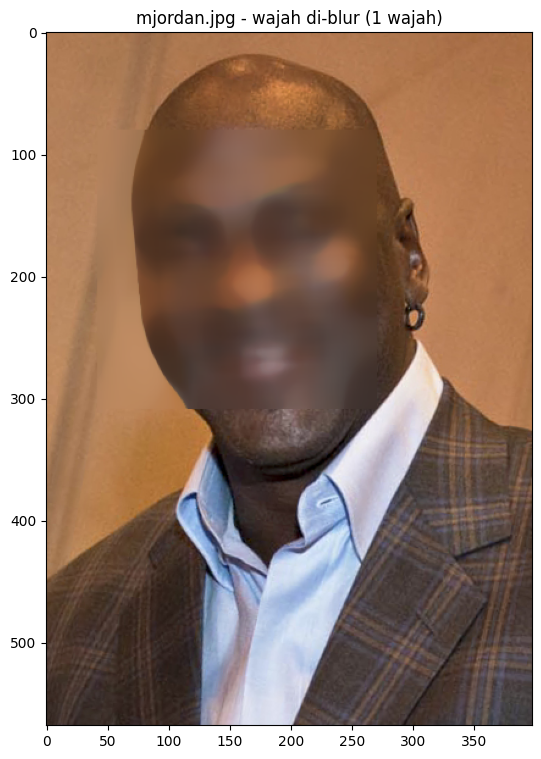

In [50]:
FILE_BLUR = None

def blur_wajah(img, faktor=0.14):
    """Median blur pada setiap wajah yang terdeteksi. Mengembalikan (gambar hasil, jumlah wajah)."""
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY) if img.ndim == 3 else img
    hasil = img.copy()
    daftar = cascade_wajah.detectMultiScale(gray)
    for (x, y, w, h) in daftar:
        k = max(7, int(min(w, h) * faktor) | 1)
        hasil[y:y + h, x:x + w] = cv.medianBlur(hasil[y:y + h, x:x + w], k)
    return hasil, len(daftar)

def wajah_tunggal(p):
    """Rasio lebar wajah terhadap lebar gambar jika gambar berisi tepat 1 wajah, selain itu 0."""
    g = cv.imread(p, cv.IMREAD_GRAYSCALE)
    r = cascade_wajah.detectMultiScale(g, 1.1, 4, minSize=(int(0.03 * g.shape[1]),) * 2)
    return r[0][2] / g.shape[1] if len(r) == 1 else 0

gambar = [p for p in gambar_di(FOLDER_FACEDET, rekursif=True) if not any(k in os.path.basename(p).lower() for k in ('reeses', 'cereal', 'ktm', 'people'))]
if FILE_BLUR:
    file_blur = cari_file(FILE_BLUR)
else:
    calon = [p for p in gambar if any(k in os.path.basename(p).lower() for k in ('jordan', 'michael', 'mj'))] or \
            [p for p in gambar if wajah_tunggal(p) > 0]
    if not calon:
        raise FileNotFoundError(f'Foto untuk blurring tidak ditemukan. Isi facedet: {[os.path.basename(p) for p in gambar]}')
    file_blur = max(calon, key=wajah_tunggal)
print('Gambar:', os.path.basename(file_blur))

asli = baca_path(file_blur)
hasil, jumlah = blur_wajah(asli)
plt.figure(figsize=(7, 9))
plt.imshow(rgb(hasil))
plt.title(f'{os.path.basename(file_blur)} - wajah di-blur ({jumlah} wajah)')
plt.show()


## 14. Mengolah gambar KTM masing-masing

### a. Gambar KTM

Gambar KTM          : /content/drive/MyDrive/PCVK/Images/244107020212/KTM1d.jpg
KTM + barang lain   : /content/drive/MyDrive/PCVK/Images/244107020212/KTMbarang.jpeg
File lain bernama ktm: ['KTM lama.jpg', 'KTM1a.jpg', 'KTM1b.jpg', 'KTM1c.jpg', 'KTMbarang.jpeg']


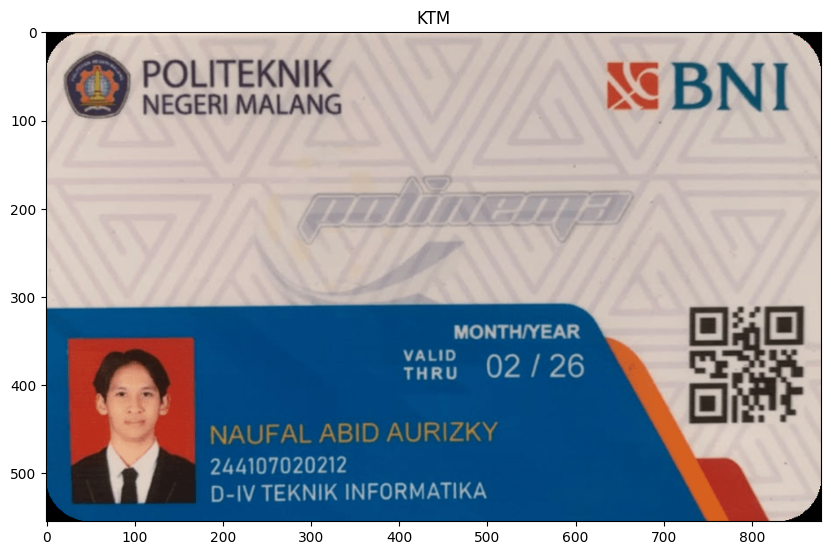

In [56]:
FILE_KTM        = 'KTM1d.jpg'
FILE_KTM_BARANG = 'KTMbarang.jpeg'

KATA_SCENE = ('barang', 'bersama', 'scene', 'lain', 'objek', 'meja', 'campur', 'multi', 'tumpuk')

FILE_KTM = cari_file(FILE_KTM)
semua_ktm = [p for p in gambar_di(ROOT_PCVK, rekursif=True) if 'ktm' in os.path.basename(p).lower()]
if FILE_KTM_BARANG is None:
    scene = [p for p in semua_ktm if p != FILE_KTM and any(k in os.path.basename(p).lower() for k in KATA_SCENE)]
    FILE_KTM_BARANG = scene[0] if scene else None
else:
    FILE_KTM_BARANG = cari_file(FILE_KTM_BARANG)

print('Gambar KTM          :', FILE_KTM)
print('KTM + barang lain   :', FILE_KTM_BARANG)
print('File lain bernama ktm:', [os.path.basename(p) for p in semua_ktm if p != FILE_KTM])

ktm_bgr = baca_path(FILE_KTM)
tampil(rgb(ktm_bgr), 'KTM', ukuran=(10, 7))

### b. Tampilkan foto KTM

Koordinat foto (x1, y1, x2, y2): (24, 352, 174, 553) | metode: proporsi wajah


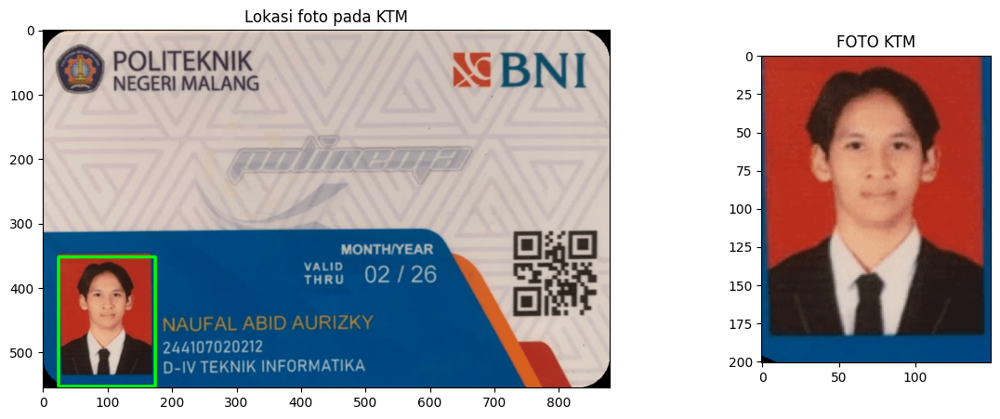

True

In [52]:
KOORDINAT_FOTO = None

def klip(v, a, b):
    return int(max(a, min(b, v)))

def deteksi_wajah_utama(img_bgr):
    """Wajah terbesar pada gambar (mencoba beberapa cascade & parameter)."""
    gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
    W = gray.shape[1]
    for xml in ('haarcascade_frontalface_alt2.xml', 'haarcascade_frontalface_alt.xml', 'haarcascade_frontalface_default.xml'):
        casc = muat_cascade(xml)
        for mn in (5, 3):
            r = casc.detectMultiScale(gray, 1.1, mn, minSize=(int(0.03 * W), int(0.03 * W)))
            if len(r):
                return tuple(int(v) for v in max(r.tolist(), key=lambda f: f[2] * f[3]))
    return None

def kotak_foto_ktm(img_bgr, wajah):
    """Perkirakan persegi panjang foto KTM dari posisi wajah; dipertajam dengan warna latar foto (merah/biru)."""
    H, W = img_bgr.shape[:2]
    fx, fy, fw, fh = wajah

    x1, x2 = klip(fx - 0.45 * fw, 0, W - 1), klip(fx + 1.45 * fw, 1, W)
    y1, y2 = klip(fy - 0.40 * fh, 0, H - 1), klip(fy + 2.15 * fh, 1, H)

    lab = cv.cvtColor(img_bgr, cv.COLOR_BGR2LAB).astype(np.float32)
    sx0, sx1 = klip(fx - 1.3 * fw, 0, W - 1), klip(fx + 2.3 * fw, 1, W)
    sy0, sy1 = klip(fy - 1.0 * fh, 0, H - 1), klip(fy + 3.2 * fh, 1, H)
    benih = [(x1 + 6, y1 + 6), (x2 - 6, y1 + 6)]
    try:
        warna = [np.median(lab[sy - 2:sy + 3, sx - 2:sx + 3].reshape(-1, 3), axis=0) for sx, sy in benih]
        latar = np.mean(warna, axis=0)
        mask = (np.linalg.norm(lab[sy0:sy1, sx0:sx1] - latar, axis=2) < 28).astype(np.uint8)
        _, lbl, st, _ = cv.connectedComponentsWithStats(mask, connectivity=4)
        l = lbl[benih[0][1] - sy0, benih[0][0] - sx0]
        if l > 0:
            x, y, w, h = st[l, :4]
            rx1, ry1, rx2 = sx0 + x, sy0 + y, sx0 + x + w
            if 1.3 * fw < (rx2 - rx1) < 3 * fw and ry1 < fy and rx1 < fx and rx2 > fx + fw:
                ry2 = min(H, ry1 + int(1.35 * (rx2 - rx1)))
                return (int(rx1), int(ry1), int(rx2), int(ry2)), 'warna latar'
    except Exception:
        pass
    return (x1, y1, x2, y2), 'proporsi wajah'

if KOORDINAT_FOTO is None:
    wajah_ktm = deteksi_wajah_utama(ktm_bgr)
    if wajah_ktm is None:
        raise RuntimeError('Wajah pada KTM tidak terdeteksi. Isi KOORDINAT_FOTO = (x1, y1, x2, y2) secara manual.')
    KOORDINAT_FOTO, metode = kotak_foto_ktm(ktm_bgr, wajah_ktm)
else:
    metode = 'manual'
print('Koordinat foto (x1, y1, x2, y2):', KOORDINAT_FOTO, '| metode:', metode)

fx1, fy1, fx2, fy2 = KOORDINAT_FOTO
foto_ktm = ktm_bgr[fy1:fy2, fx1:fx2]

penanda = ktm_bgr.copy()
cv.rectangle(penanda, (fx1, fy1), (fx2, fy2), (0, 255, 0), tebal_garis(penanda))
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [3, 1]})
ax[0].imshow(rgb(penanda));  ax[0].set_title('Lokasi foto pada KTM')
ax[1].imshow(rgb(foto_ktm)); ax[1].set_title('FOTO KTM')
plt.show()
cv.imwrite('foto_ktm.png', foto_ktm)

### c. Deteksi obyek KTM pada gambar KTM bersama barang lain

Template : /content/drive/MyDrive/PCVK/Images/244107020212/KTM1d.jpg
Scene    : /content/drive/MyDrive/PCVK/Images/244107020212/KTMbarang.jpeg
Keypoint template: 1711 | keypoint scene: 4197 | match: 1711 | match bagus: 336
Inlier RANSAC: 258


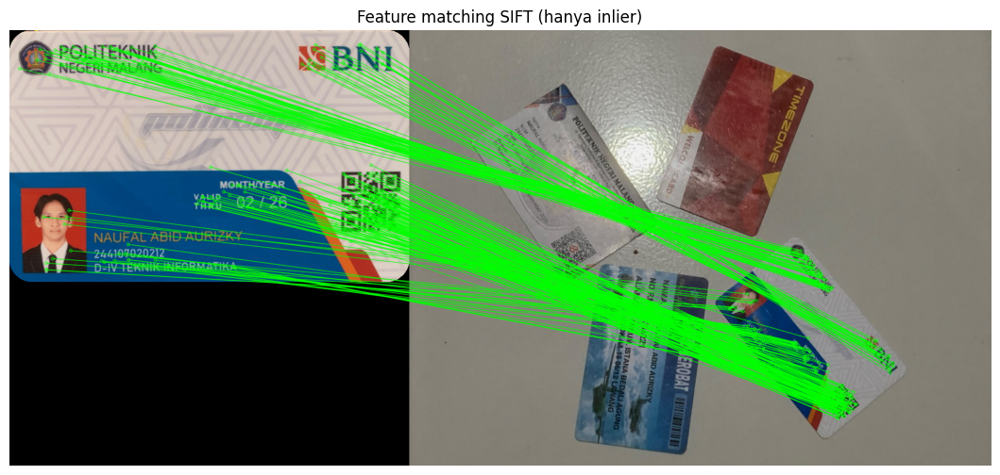

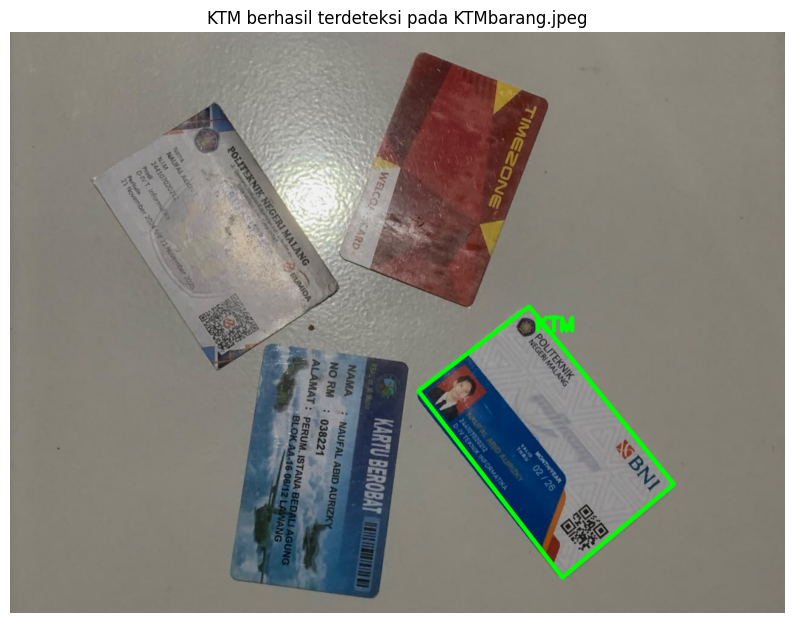

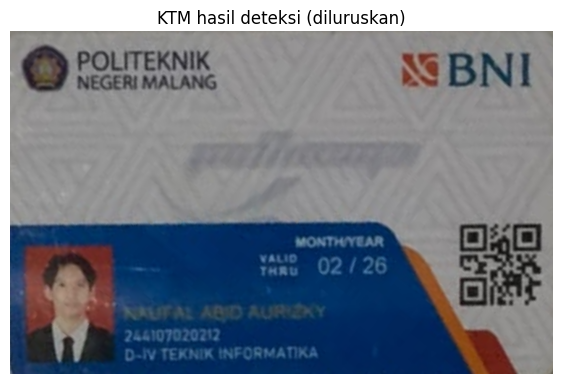

Tersimpan: hasil_deteksi_ktm.jpg


In [54]:
FILE_KTM_TEMPLATE = 'KTM1d.jpg'
FILE_KTM_SCENE    = 'KTMbarang.jpeg'

segarkan_indeks()
try:
    path_templ = cari_file(FILE_KTM_TEMPLATE)
    path_scene = cari_file(FILE_KTM_SCENE)
except FileNotFoundError:
    ada = [os.path.basename(p) for p in gambar_di(ROOT_PCVK, rekursif=True) if 'ktm' in os.path.basename(p).lower()]
    raise FileNotFoundError(f"KTM tidak ditemukan. File bernama 'ktm' di Drive: {ada}. "
                            "Pastikan nama pada FILE_KTM_TEMPLATE / FILE_KTM_SCENE sama persis.")
print('Template :', path_templ)
print('Scene    :', path_scene)

ktm_bgr    = baca_path(path_templ)
scene_asli = baca_path(path_scene)

def perkecil(img, maks_sisi=1600):
    s = min(1.0, maks_sisi / max(img.shape[:2]))
    return (cv.resize(img, None, fx=s, fy=s, interpolation=cv.INTER_AREA) if s < 1 else img)

def deteksi_obyek_fitur(templ_bgr, scene_bgr, rasio=0.75, min_cocok=10):
    templ, scene = perkecil(templ_bgr), perkecil(scene_bgr)
    g1, g2 = (cv.cvtColor(i, cv.COLOR_BGR2GRAY) for i in (templ, scene))

    sift = cv.SIFT_create()
    kp1, des1 = sift.detectAndCompute(g1, None)
    kp2, des2 = sift.detectAndCompute(g2, None)
    pasangan = cv.BFMatcher().knnMatch(des1, des2, k=2)
    bagus = [p[0] for p in pasangan if len(p) == 2 and p[0].distance < rasio * p[1].distance]
    print(f'Keypoint template: {len(kp1)} | keypoint scene: {len(kp2)} | match: {len(pasangan)} | match bagus: {len(bagus)}')

    M = poligon = inlier = None
    if len(bagus) >= min_cocok:
        src = np.float32([kp1[m.queryIdx].pt for m in bagus]).reshape(-1, 1, 2)
        dst = np.float32([kp2[m.trainIdx].pt for m in bagus]).reshape(-1, 1, 2)
        M, inl = cv.findHomography(src, dst, cv.RANSAC, 5.0)
        if M is not None:
            h, w = g1.shape
            sudut = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
            poligon = cv.perspectiveTransform(sudut, M)
            inlier = inl.ravel().tolist()
            print('Inlier RANSAC:', int(sum(inlier)))
    return templ, scene, kp1, kp2, bagus, M, poligon, inlier

def valid(poligon, inlier, scene):
    """KTM dianggap terdeteksi jika inlier cukup, bentuknya cembung, dan luasnya wajar."""
    return (poligon is not None and sum(inlier) >= 10 and cv.isContourConvex(np.int32(poligon))
            and 0.01 * scene.shape[0] * scene.shape[1] < cv.contourArea(poligon) < 1.5 * scene.shape[0] * scene.shape[1])

for rasio in (0.75, 0.80):
    templ, scene, kp1, kp2, bagus, M, poligon, inlier = deteksi_obyek_fitur(ktm_bgr, scene_asli, rasio=rasio)
    if valid(poligon, inlier, scene):
        break

if valid(poligon, inlier, scene):
    hasil = scene.copy()
    t = tebal_garis(hasil)
    cv.polylines(hasil, [np.int32(poligon)], True, (0, 255, 0), t, cv.LINE_AA)
    cv.putText(hasil, 'KTM', tuple(np.int32(poligon[0, 0]) + [10, 40]), cv.FONT_HERSHEY_SIMPLEX,
               max(1.0, scene.shape[1] / 1200), (0, 255, 0), t)
    garis_cocok = cv.drawMatches(templ, kp1, scene, kp2, bagus, None, matchesMask=inlier,
                                 matchColor=(0, 255, 0), flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    h, w = templ.shape[:2]
    ktm_lurus = cv.warpPerspective(scene, np.linalg.inv(M), (w, h))

    plt.figure(figsize=(16, 6)); plt.imshow(rgb(garis_cocok)); plt.title('Feature matching SIFT (hanya inlier)'); plt.axis('off'); plt.show()
    plt.figure(figsize=(10, 8)); plt.imshow(rgb(hasil)); plt.title(f'KTM berhasil terdeteksi pada {os.path.basename(path_scene)}'); plt.axis('off'); plt.show()
    plt.figure(figsize=(7, 5)); plt.imshow(rgb(ktm_lurus)); plt.title('KTM hasil deteksi (diluruskan)'); plt.axis('off'); plt.show()
    cv.imwrite('hasil_deteksi_ktm.jpg', hasil)
    print('Tersimpan: hasil_deteksi_ktm.jpg')
else:
    print('KTM TIDAK terdeteksi (match terlalu sedikit / bentuk tidak valid). '
          'Coba foto yang lebih terang, KTM lebih besar/tidak tertutup, dan tidak terlalu miring.')

# D3. Tugas Pengayaan: Pengenalan Karakter KTM dengan CNN

### 1. Persiapan dataset digit 0-9

29 font valid untuk membuat dataset sintetis
Dataset sintetis dibuat di dataset/training -> 400 gambar per digit


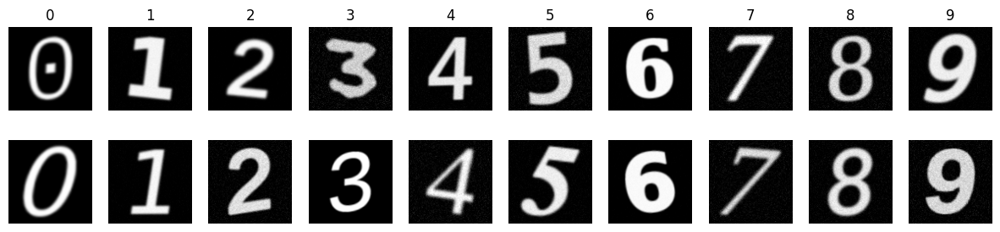

In [57]:
import random, glob, pickle, shutil
import matplotlib, matplotlib.font_manager as fm
from PIL import Image, ImageDraw, ImageFont

LEBAR, TINGGI = 100, 100

def normalisasi_karakter(g, pad=0.12):
    """Gambar abu-abu (karakter terang, latar gelap) : crop ketat, jadikan persegi, ukuran 100x100."""
    g = g.astype(np.uint8)
    ys, xs = np.where(g > max(30, g.max() * 0.25))
    if len(xs) == 0:
        return np.zeros((TINGGI, LEBAR), np.uint8)
    g = g[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = g.shape
    sisi = int(max(h, w) * (1 + 2 * pad))
    kanvas = np.zeros((sisi, sisi), np.uint8)
    kanvas[(sisi - h) // 2:(sisi - h) // 2 + h, (sisi - w) // 2:(sisi - w) // 2 + w] = g
    return cv.resize(kanvas, (LEBAR, TINGGI), interpolation=cv.INTER_AREA)

dataset_user = [d for d in ('dataset/training', os.path.join(BASE, 'dataset', 'training')) if os.path.isdir(d)
                and len([x for x in os.listdir(d) if os.path.isdir(os.path.join(d, x))]) >= 10]

if dataset_user:
    DATADIR = dataset_user[0]
    print('Memakai dataset buatan sendiri:', DATADIR)
else:
    DATADIR = 'dataset/training'
    JUMLAH_PER_KELAS = 400
    HURUF_BUANG = ('cmex', 'cmsy', 'cmmi', 'cmb', 'cmr', 'cmss', 'cmtt', 'stixsiz', 'stixnonuni', 'symbol', 'dingbat',
                   'emoji', 'awesome', 'icon', 'wingding', 'material', 'lastresort', 'math')

    def font_valid(path):
        """Font dipakai jika ke-10 angkanya berbeda satu sama lain (bukan font simbol / kotak kosong)."""
        if any(k in os.path.basename(path).lower() for k in HURUF_BUANG):
            return False
        try:
            f = ImageFont.truetype(path, 60)
            bm = []
            for ch in '0123456789':
                im = Image.new('L', (90, 90), 0); ImageDraw.Draw(im).text((10, 5), ch, font=f, fill=255)
                bm.append(np.asarray(im).tobytes())
            return len(set(bm)) == 10
        except Exception:
            return False

    semua_font = fm.findSystemFonts(fontext='ttf') + glob.glob(os.path.join(matplotlib.get_data_path(), 'fonts', 'ttf', '*.ttf'))
    semua_font = sorted(set(f for f in semua_font if font_valid(f)))
    print(f'{len(semua_font)} font valid untuk membuat dataset sintetis')

    def buat_sampel(ch, rng):
        f = ImageFont.truetype(rng.choice(semua_font), rng.randint(70, 120))
        im = Image.new('L', (220, 220), 0)
        d = ImageDraw.Draw(im)
        l, t, r, b = d.textbbox((0, 0), ch, font=f, stroke_width=2)
        d.text(((220 - (r - l)) // 2 - l, (220 - (b - t)) // 2 - t), ch, font=f, fill=255, stroke_width=rng.choice([0, 0, 1, 2]))
        a = np.asarray(im)

        M = cv.getRotationMatrix2D((110, 110), rng.uniform(-10, 10), rng.uniform(0.85, 1.1))
        M[0, 1] += rng.uniform(-0.15, 0.15)
        a = cv.warpAffine(a, M, (220, 220))
        k = np.ones((2, 2), np.uint8)
        if rng.random() < 0.3: a = cv.erode(a, k)
        elif rng.random() < 0.3: a = cv.dilate(a, k)
        a = normalisasi_karakter(a, pad=rng.uniform(0.05, 0.2)).astype(np.float32)
        a = cv.GaussianBlur(a, (0, 0), rng.uniform(0.3, 1.6))
        a = a * rng.uniform(0.6, 1.0) + np.random.normal(0, rng.uniform(0, 12), a.shape)
        return np.clip(a, 0, 255).astype(np.uint8)

    if os.path.isdir('dataset'):
        shutil.rmtree('dataset')
    rng = random.Random(42); np.random.seed(42)
    for ch in '0123456789':
        os.makedirs(os.path.join(DATADIR, ch), exist_ok=True)
        for i in range(JUMLAH_PER_KELAS):
            cv.imwrite(os.path.join(DATADIR, ch, f'{i:04d}.png'), buat_sampel(ch, rng))
    print('Dataset sintetis dibuat di', DATADIR, '->', JUMLAH_PER_KELAS, 'gambar per digit')

kelas_contoh = sorted(os.listdir(DATADIR))
fig, ax = plt.subplots(2, 10, figsize=(15, 3.2))
for j, c in enumerate(kelas_contoh[:10]):
    isi = sorted(os.listdir(os.path.join(DATADIR, c)))
    for r in range(2):
        ax[r, j].imshow(cv.imread(os.path.join(DATADIR, c, isi[r]), 0), cmap='gray'); ax[r, j].axis('off')
    ax[0, j].set_title(c)
plt.show()

### 2. Persiapan data untuk training

In [58]:
import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

width, height = 100, 100

dirs = sorted(os.listdir(DATADIR))
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
            new_array = cv2.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X, open("X.pickle", "wb"))
pickle.dump(Y, open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data :", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

9: 100%|██████████| 400/400 [00:00<00:00, 7207.02it/s]


jumlah data : 4000
jumlah kelas: 10 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


### 3. Training data (CNN)

Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 34s 316ms/step - accuracy: 0.8466 - loss: 0.6553 - val_accuracy: 0.9937 - val_loss: 0.0249
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 39s 387ms/step - accuracy: 0.9900 - loss: 0.0321 - val_accuracy: 1.0000 - val_loss: 0.0068
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 36s 334ms/step - accuracy: 0.9981 - loss: 0.0095 - val_accuracy: 1.0000 - val_loss: 0.0023
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 42s 345ms/step - accuracy: 0.9969 - loss: 0.0100 - val_accuracy: 1.0000 - val_loss: 0.0032
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 33s 328ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 1.0000 - val_loss: 7.3405e-04
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 33s 329ms/step - accuracy: 1.0000 - loss: 3.5531e-04 - val_accuracy: 1.0000 - val_loss: 5.4085e-04
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 41s 333ms/step - accuracy: 1.0000 - loss: 2.1185e-04 - val_accuracy: 1.0000 - val_loss: 4.4973e-04
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 42s 341ms/step - accura

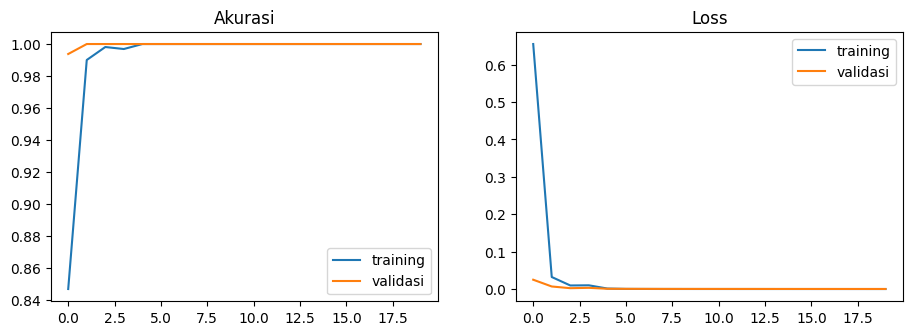

In [59]:
EPOCHS = 20

import pickle
from keras.layers import (Input, Conv2D, MaxPooling2D,
                          Flatten, Dense, ZeroPadding2D)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]

inputs     = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten   = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64,  activation='relu')(fc_layer)
outputs  = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=EPOCHS, verbose=1, validation_split=0.2)
model.save('anpr.keras')

print("akurasi training :", riwayat.history['accuracy'][-1])
print("akurasi validasi :", riwayat.history['val_accuracy'][-1])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(riwayat.history['accuracy'], label='training'); ax[0].plot(riwayat.history['val_accuracy'], label='validasi')
ax[0].set_title('Akurasi'); ax[0].legend()
ax[1].plot(riwayat.history['loss'], label='training'); ax[1].plot(riwayat.history['val_loss'], label='validasi')
ax[1].set_title('Loss'); ax[1].legend()
plt.show()

### 4. Segmentasi karakter NIM pada KTM

Komponen terdeteksi: 12 | digit yang dipisahkan: 12
Jumlah karakter terdeteksi pada baris NIM: 12


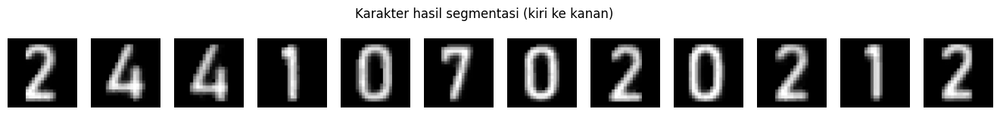

In [64]:
ROI_NIM = None
JUMLAH_DIGIT = 12

def segmentasi_nim(ktm_img, kotak_foto, roi_manual=None, jumlah=JUMLAH_DIGIT):
    H, W = ktm_img.shape[:2]
    x1, y1, x2, y2 = kotak_foto
    pw, ph = x2 - x1, y2 - y1
    if roi_manual is None:
        rx1, rx2 = x2 + int(0.03 * pw), min(W, x2 + int(3.6 * pw))
        ry1, ry2 = y1 + int(0.55 * ph), min(H, y2 + int(0.08 * ph))
    else:
        rx1, ry1, rx2, ry2 = roi_manual
    roi = ktm_img[ry1:ry2, rx1:rx2]
    B, G, R = [c.astype(np.float32) for c in cv.split(roi)]

    gray  = cv.GaussianBlur(cv.cvtColor(roi, cv.COLOR_BGR2GRAY), (3, 3), 0).astype(np.float32)
    latar = cv.GaussianBlur(gray, (0, 0), 0.25 * ph)
    mask  = ((gray - latar > 18) & (B >= 0.85 * R)).astype(np.uint8) * 255
    mask  = cv.morphologyEx(mask, cv.MORPH_CLOSE, np.ones((2, 2), np.uint8))

    n, lbl, st, _ = cv.connectedComponentsWithStats(mask, connectivity=8)
    komp = [(i, *st[i]) for i in range(1, n)                       # (id, x, y, w, h, area)
            if 0.05 * ph <= st[i][3] <= 0.25 * ph and st[i][2] <= 0.25 * ph and st[i][4] >= 0.001 * ph * ph]
    komp.sort(key=lambda k: k[2] + k[4] / 2)
    baris = []
    for k in komp:
        yc = k[2] + k[4] / 2
        for b in baris:
            if abs(yc - np.mean([c[2] + c[4] / 2 for c in b])) < 0.5 * np.median([c[4] for c in b]):
                b.append(k); break
        else:
            baris.append([k])
    baris = [b for b in baris if len(b) >= 5 and np.std([c[4] for c in b]) < 0.3 * np.mean([c[4] for c in b])]
    if not baris:
        raise RuntimeError('Baris NIM tidak ditemukan. Isi ROI_NIM secara manual (x1, y1, x2, y2).')
    b = min(baris, key=lambda b: np.mean([c[2] for c in b]))
    xs0, xs1 = min(c[1] for c in b), max(c[1] + c[3] for c in b)
    ys0, ys1 = min(c[2] for c in b), max(c[2] + c[4] for c in b)
    garis = np.isin(lbl, [c[0] for c in b]).astype(np.uint8)[ys0:ys1, xs0:xs1]
    gr    = R[ys0:ys1, xs0:xs1]
    Wb    = xs1 - xs0

    nk, _, sk, _ = cv.connectedComponentsWithStats(garis, connectivity=8)
    urut = sorted(range(1, nk), key=lambda i: sk[i][0])
    if len(urut) == jumlah:
        batas = [0] + [int((sk[a][0] + sk[a][2] + sk[c][0]) / 2) for a, c in zip(urut[:-1], urut[1:])] + [Wb]
    else:
        proj = cv.GaussianBlur(garis.sum(0).astype(np.float32).reshape(1, -1), (0, 0), 1.0).ravel()
        sel = Wb / jumlah
        batas = [0]
        for k in range(1, jumlah):
            c, r = int(round(k * sel)), int(0.3 * sel)
            lo, hi = max(batas[-1] + 2, c - r), min(Wb - 1, c + r)
            batas.append(lo + int(np.argmin(proj[lo:hi + 1])) if hi > lo else c)
        batas.append(Wb)
    print(f'Komponen terdeteksi: {len(urut)} | digit yang dipisahkan: {jumlah}')

    hasil = []
    for i in range(jumlah):
        a, z = batas[i], batas[i + 1]
        m = np.zeros_like(garis); m[:, a:z] = garis[:, a:z]
        if m.sum() == 0:
            continue
        ys, xs = np.where(m > 0)
        y0, y1c, xa, xz = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
        m = cv.dilate(m, np.ones((3, 3), np.uint8))
        p = 2
        crop = (gr * (m > 0))[max(0, y0 - p):y1c + p, max(0, xa - p):xz + p]
        crop = np.clip(crop / max(np.percentile(crop[crop > 0], 99), 1) * 255, 0, 255)
        hasil.append(((rx1 + xs0 + xa, ry1 + ys0 + y0, xz - xa, y1c - y0), normalisasi_karakter(crop)))
    return hasil

karakter = segmentasi_nim(ktm_bgr, KOORDINAT_FOTO, ROI_NIM)
print('Jumlah karakter terdeteksi pada baris NIM:', len(karakter))
if len(karakter) != JUMLAH_DIGIT:
    print(f'PERINGATAN: diharapkan {JUMLAH_DIGIT} karakter. Periksa ROI_NIM.')

shutil.rmtree('dataset/testing', ignore_errors=True)
os.makedirs('dataset/testing/KTM', exist_ok=True)
for i, (_, c) in enumerate(karakter):
    cv.imwrite(f'dataset/testing/KTM/{i:02d}.png', c)

fig, ax = plt.subplots(1, len(karakter), figsize=(1.4 * len(karakter), 1.8))
for a, (_, c) in zip(np.ravel(ax), karakter):
    a.imshow(c, cmap='gray'); a.axis('off')
plt.suptitle('Karakter hasil segmentasi (kiri ke kanan)')
plt.show()

### 5. Testing - Pengenalan Karakter

folder name: KTM no: 246107020212

NIM terbaca pada KTM : 246107020212 (12 digit)
Keyakinan per digit  : 1.00 0.56 0.95 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00
Digit dengan keyakinan < 0,90 (periksa posisi ke-): [2]


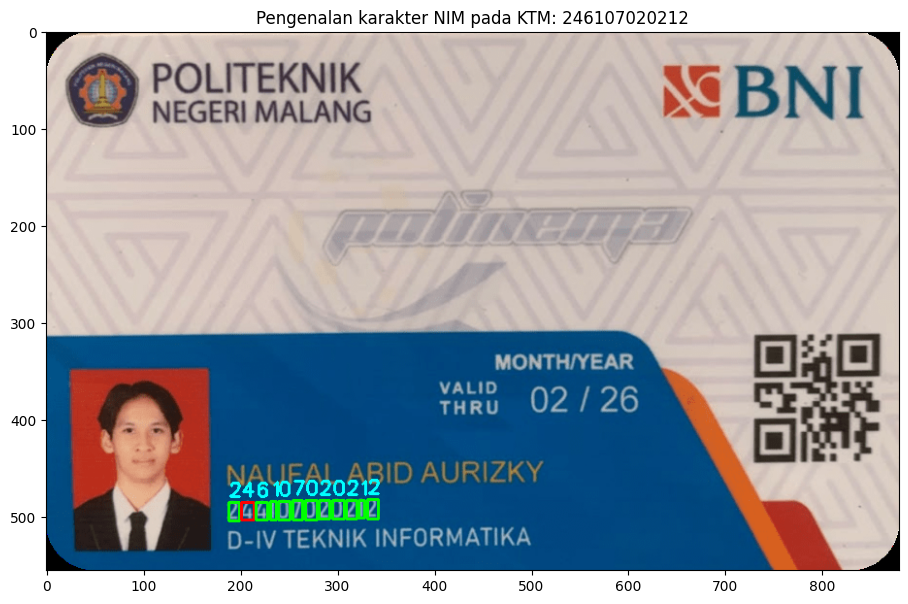

NIM sebenarnya       : 244107020212  -> 11/12 karakter benar (92%)


In [67]:
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = "dataset/testing"
width, height = 100, 100

model = tf.keras.models.load_model("anpr.keras")
dirs  = pickle.load(open("kelas.pickle", "rb"))

for car in sorted(os.listdir(data_dir_testing)):
    temp, yakin = "", []
    folder = os.path.join(data_dir_testing, car)
    for char_img in sorted(os.listdir(folder)):
        img_array = cv2.imread(os.path.join(folder, char_img),
                               cv2.IMREAD_GRAYSCALE)
        new_array = cv2.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]
        yakin.append(float(np.max(prediction[0])))
    print("folder name: {} no: {}".format(car, temp))

NIM_HASIL = temp
print('\nNIM terbaca pada KTM :', NIM_HASIL, f'({len(NIM_HASIL)} digit)')
print('Keyakinan per digit  :', ' '.join(f'{c:.2f}' for c in yakin))
ragu = [i + 1 for i, c in enumerate(yakin) if c < 0.90]
if ragu:
    print('Digit dengan keyakinan < 0,90 (periksa posisi ke-):', ragu)

anotasi = ktm_bgr.copy()
for ((x, y, w, h), _), ch, c in zip(karakter, NIM_HASIL, yakin):
    warna = (0, 255, 0) if c >= 0.90 else (0, 0, 255)
    cv.rectangle(anotasi, (x, y), (x + w, y + h), warna, max(1, tebal_garis(anotasi) // 2))
    cv.putText(anotasi, ch, (x, max(15, y - 6)), cv.FONT_HERSHEY_SIMPLEX, max(0.6, anotasi.shape[1] / 1300), (255, 255, 0), max(1, tebal_garis(anotasi) // 2))
tampil(rgb(anotasi), 'Pengenalan karakter NIM pada KTM: ' + NIM_HASIL, ukuran=(11, 7))

NIM_KTM = NIM
if len(NIM_KTM) == len(NIM_HASIL):
    benar = sum(a == b for a, b in zip(NIM_KTM, NIM_HASIL))
    print(f'NIM sebenarnya       : {NIM_KTM}  -> {benar}/{len(NIM_KTM)} karakter benar ({100 * benar / len(NIM_KTM):.0f}%)')
else:
    print(f'(Panjang NIM terbaca {len(NIM_HASIL)} != panjang NIM pada variabel NIM ({len(NIM_KTM)}); periksa segmentasi pada langkah 4.)')